# Driven coherence during a g1e0 sideband

$$H = g(t)\,(a^\dagger\sigma_- + a\,\sigma_+),\qquad \dot\rho=-i[H,\rho]+\sum_k \mathcal D[L_k]\rho,\qquad \mathcal D[L]\rho=L\rho L^\dagger-\tfrac12\{L^\dagger L,\rho\}$$

| $L_k$ | rate | decays |
|---|---|---|
| $\sigma_-$ | $\Gamma_{1q}$ | qubit population |
| $\sigma_z$ | $\Gamma_{\phi q}/2$ | qubit coherence at $\Gamma_{\phi q}$ |
| $a$ | $\Gamma_{1c}$ | cavity population |
| $a^\dagger a$ | $2\Gamma_{\phi c}$ | cavity 0–1 coherence at $\Gamma_{\phi c}$ |

$\Gamma_2=\Gamma_1/2+\Gamma_\phi$. One excitation: the states are $\lvert g0\rangle,\lvert e0\rangle,\lvert g1\rangle$. Unknowns: the four rates **while the sideband is on**.

**The qubit and the cavity have different rates**: $\Gamma_{1q}\neq\Gamma_{1c}$ and $\Gamma_{\phi q}\neq\Gamma_{\phi c}$ (subscript $q$ = qubit, $c$ = cavity). The protocol-1 and protocol-2 quantities $\kappa_1$, $\kappa_\phi$, $\bar\Gamma_2$ are **averages** of the two modes, not rates of either one, so they are quoted as rates only: $1/\kappa_1$ is not the lifetime of anything. Protocol 3 separates the modes, so it quotes each mode's rate **and** time ($T_1$, $T_\phi$).

**Notation**, the same in this notebook and in the runtimes (`runtimes/sideband_calibration`):

| here | meaning | runtime name |
|---|---|---|
| $\Gamma_{1q}=1/T_{1q}$ | qubit decay rate during the sideband | `G1q` (table row "T1 qubit") |
| $\Gamma_{\phi q}=1/T_{\phi q}$ | qubit pure dephasing | `Gphiq` ("Tphi qubit") |
| $\Gamma_{1c}=1/T_{1c}$ | cavity decay rate | `G1c` ("T1 cavity") |
| $\Gamma_{\phi c}=1/T_{\phi c}$ | cavity pure dephasing | `Gphic` ("Tphi cavity") |
| $\Gamma_{2q},\ \Gamma_{2c}$ | Ramsey decay, $\Gamma_1/2+\Gamma_\phi$ of each mode | `G2q`, `G2c` |
| $\kappa_1=\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}$ | protocol 1, decay of the population | `kappa_1` |
| $\kappa_\phi=\tfrac{\Gamma_{\phi q}+\Gamma_{\phi c}}{2}$ | protocol 1, extra decay of the oscillation | `kappa_phi` |
| $\bar\Gamma_2=\tfrac{\Gamma_{2q}+\Gamma_{2c}}{2}$ | protocol 2, echo decay | `G2_bar` |
| $t_\text{swap}$, $\phi_0$ | protocol 1 fit: full-swap time, phase offset | `t_swap`, `phi_0` |
| $\theta$ | rotation $g\,t$ of one interleave pulse | `theta` |

1. Theory: how each protocol's rate follows from these equations; 1.5 the e1f0 sideband (transmon g, e, f), 1.6 a cavity-cavity beamsplitter, 1.7 how every number on the GUI pages follows from the fit and the master equation
2. Each protocol simulated as on the device and fitted with the runtime's own analysis
3. Extracted vs true rates

# 0. Setup: truth, pulses, operators

In [1]:
import sys
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from scipy.linalg import expm

sys.path.insert(0, "/home/tunmays_rsl_pc_wsl/boson/msmt_workbench")       # the runtimes' analysis functions
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_oscillation import fit_oscillation, oscillation_model
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_echo import fit_fringe, fit_decay
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_coherence import PREPS, fit_mode_model

# ---------------- truth (rates while the sideband is on) ----------------
T1q, Tphiq, T1c, Tphic = 30e-6, 40e-6, 300e-6, 1e-3
G1q, Gpq, G1c, Gpc = 1 / T1q, 1 / Tphiq, 1 / T1c, 1 / Tphic
G2q, G2c = G1q / 2 + Gpq, G1c / 2 + Gpc
# ---------------- pulses ----------------
fs = 800e6                         # DAC sample rate
ramp = 10e-9                       # hann ramp of the swap pulse (rise ramp/2, fall ramp/2)
swap_flat = 310.6e-9               # Q1C1_swap flat
shots = 4000
readout = lambda p: 0.03 + 0.92 * p    # readout error (the fits' amplitudes / offsets absorb it)
rng = np.random.default_rng(11)


def hann(flat):
    """Envelope samples of a hann pulse (ramp, flat) at fs, peak 1."""
    n_ramp, n_flat = int(round(ramp * fs)), int(round(flat * fs))
    rise = np.sin(np.pi / 2 * (np.arange(n_ramp // 2) + 0.5) / (n_ramp // 2)) ** 2
    return np.concatenate([rise, np.ones(n_flat), rise[::-1]])


swap_area = np.sum(hann(swap_flat))                   # its samples add up to g t = pi/2
g_peak = (np.pi / 2) / (swap_area / fs)              # rad/s at envelope 1
print(f"g/2pi = {g_peak / 2 / np.pi / 1e6:.3f} MHz, full swap {np.pi / 2 / g_peak * 1e9:.1f} ns of flat-top time")

# ---------------- master equation, qubit (x) cavity, one excitation ----------------
sm = qt.tensor(qt.destroy(2), qt.qeye(2)); a = qt.tensor(qt.qeye(2), qt.destroy(2))
c_ops = [np.sqrt(G1q) * sm, np.sqrt(Gpq / 2) * (2 * sm.dag() * sm - 1), np.sqrt(G1c) * a, np.sqrt(2 * Gpc) * a.dag() * a]
H_ex = a.dag() * sm + a * sm.dag()
L_of = lambda gg: qt.liouvillian(gg * H_ex, c_ops).full()
NQ = (sm.dag() * sm).full()
vec = lambda k: qt.ket2dm(k).full().ravel(order="F")
P_e = lambda v: float(np.real(np.trace(NQ @ v.reshape(4, 4, order="F"))))
sup = lambda U: np.kron(U.full().conj(), U.full())
qrot = lambda th, ph: sup(qt.tensor((-1j * th / 2 * (np.cos(ph) * qt.sigmax() + np.sin(ph) * qt.sigmay())).expm(), qt.qeye(2)))
SWAP = sup((-1j * np.pi / 2 * H_ex).expm())            # ideal swap (preparation / readout)
g0 = vec(qt.tensor(qt.basis(2, 0), qt.basis(2, 0)))
phases = np.arange(8) * 2 * np.pi / 8                 # closing pi/2 phases (as the runtimes)


def envelope_map(env, sign=+1):
    """Superoperator of a pulse with envelope samples env (sign -1 = J^dag), piecewise constant per sample."""
    S = np.eye(16, dtype=complex)
    for e in env:
        S = expm(L_of(sign * g_peak * e) / fs) @ S
    return S


def sideband_map(t_total, sign=+1):
    """A stretched sideband of total length t_total: hann rise, constant flat, hann fall."""
    rise = hann(0.0)[: int(round(ramp * fs)) // 2]
    return envelope_map(rise[::-1], sign) @ expm(L_of(sign * g_peak) * (t_total - ramp)) @ envelope_map(rise, sign)


def measure(p):
    """Binomial shots of readout(p); returns (P, sigma) as the runtimes compute them."""
    k = rng.binomial(shots, readout(np.asarray(p)))
    P = k / shots
    pt = (P * shots + 0.5) / (shots + 1)
    return P, np.sqrt(pt * (1 - pt) / shots)

g/2pi = 0.794 MHz, full swap 315.0 ns of flat-top time


# 1. Theory

## 1.0 Equations of motion, term by term

States $\lvert g0\rangle,\lvert e0\rangle,\lvert g1\rangle$ (one excitation at most; nothing raises it). Write $e\equiv e0$, $c\equiv g1$, $0\equiv g0$.

$$H=g(t)\,\big(\lvert e\rangle\langle c\rvert+\lvert c\rangle\langle e\rvert\big)$$

**Loss**, $L=\sqrt{\Gamma}\,\lvert 0\rangle\langle x\rvert$ ($x=e$: $\sigma_-$, $\Gamma_{1q}$; $x=c$: $a$, $\Gamma_{1c}$):

$$\mathcal D[L]\rho=\Gamma\Big(\rho_{xx}\lvert0\rangle\langle0\rvert-\tfrac12\{\lvert x\rangle\langle x\rvert,\rho\}\Big)
\;\Rightarrow\;\dot\rho_{xx}\mathrel{-}=\Gamma\rho_{xx},\quad \dot\rho_{xj}\mathrel{-}=\tfrac{\Gamma}{2}\rho_{xj}\ (j\neq x),\quad \dot\rho_{00}\mathrel{+}=\Gamma\rho_{xx}$$

**Qubit dephasing**, $L=\sqrt{\Gamma_{\phi q}/2}\,\sigma_z$ with $\sigma_z=\mathrm{diag}(-1,+1,-1)$ on $(0,e,c)$:

$$\mathcal D[L]\rho=\tfrac{\Gamma_{\phi q}}{2}(\sigma_z\rho\sigma_z-\rho)\;\Rightarrow\;\dot\rho_{ij}\mathrel{-}=\tfrac{\Gamma_{\phi q}}{2}(1-s_is_j)\rho_{ij}=\Gamma_{\phi q}\rho_{ij}\ \text{ if the qubit differs } (s_i\neq s_j)$$

**Cavity dephasing**, $L=\sqrt{2\Gamma_{\phi c}}\,a^\dagger a$ with $n=\mathrm{diag}(0,0,1)$:

$$\mathcal D[L]\rho=2\Gamma_{\phi c}\big(n\rho n-\tfrac12\{n^2,\rho\}\big)\;\Rightarrow\;\dot\rho_{ij}\mathrel{-}=\Gamma_{\phi c}(n_i-n_j)^2\rho_{ij}=\Gamma_{\phi c}\rho_{ij}\ \text{ if the photon number differs}$$

**Hamiltonian**, $\dot\rho=-i[H,\rho]$: $(H\rho)_{ij}=g\,\rho_{\bar i j}$ with $\bar e=c$, $\bar c=e$, and $0$ for $i=0$.

Collecting, with $p_e=\rho_{ee}$, $p_c=\rho_{cc}$, $c_{ec}=\rho_{ec}$, $u=\rho_{e0}$, $w=\rho_{c0}$:

$$\begin{aligned}
\dot p_e &= -2g\,\mathrm{Im}\,c_{ec}-\Gamma_{1q}p_e\\
\dot p_c &= +2g\,\mathrm{Im}\,c_{ec}-\Gamma_{1c}p_c\\
\dot c_{ec} &= -ig\,(p_c-p_e)-\big(\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}+\Gamma_{\phi q}+\Gamma_{\phi c}\big)c_{ec}\\
\dot u &= -ig\,w-\Gamma_{2q}\,u,\qquad \Gamma_{2q}=\tfrac{\Gamma_{1q}}{2}+\Gamma_{\phi q}\\
\dot w &= -ig\,u-\Gamma_{2c}\,w,\qquad \Gamma_{2c}=\tfrac{\Gamma_{1c}}{2}+\Gamma_{\phi c}
\end{aligned}$$

$e$ vs $c$ differ in the qubit **and** in the photon number, so both dephasings act. $e$ vs $0$ differ only in the qubit; $c$ vs $0$ differ only in the photon number. No jump term feeds $u$ or $w$.

**Check:** these five equations against qutip's Liouvillian, applied to random states.

In [2]:
# 1.0 check: the hand-derived equations vs qutip's Liouvillian (qubit (x) cavity, cavity truncated at 2)
L_full = qt.liouvillian(g_peak * H_ex, c_ops).full()
idx = {"0": (0, 0), "e": (1, 0), "c": (0, 1)}                    # (qubit, photon) -> flat index q*2 + n
k_ = lambda s: 2 * idx[s][0] + idx[s][1]
worst = 0.0
for trial in range(20):
    psi = rng.normal(size=3) + 1j * rng.normal(size=3)              # random state in span{0, e, c}
    full = np.zeros(4, complex); full[[k_("0"), k_("e"), k_("c")]] = psi / np.linalg.norm(psi)
    rho = np.outer(full, full.conj())
    drho = (L_full @ rho.ravel(order="F")).reshape(4, 4, order="F")
    r = lambda i, j: rho[k_(i), k_(j)]
    d = lambda i, j: drho[k_(i), k_(j)]
    gg = g_peak
    pred = {
        "p_e": -2 * gg * r("e", "c").imag - G1q * r("e", "e"),
        "p_c": +2 * gg * r("e", "c").imag - G1c * r("c", "c"),
        "c_ec": -1j * gg * (r("c", "c") - r("e", "e")) - ((G1q + G1c) / 2 + Gpq + Gpc) * r("e", "c"),
        "u": -1j * gg * r("c", "0") - G2q * r("e", "0"),
        "w": -1j * gg * r("e", "0") - G2c * r("c", "0"),
    }
    got = {"p_e": d("e", "e"), "p_c": d("c", "c"), "c_ec": d("e", "c"), "u": d("e", "0"), "w": d("c", "0")}
    for key in pred:
        worst = max(worst, abs(pred[key] - got[key]) / g_peak)
print(f"20 random states, 5 equations: max |hand - qutip| / g = {worst:.1e}")
assert worst < 1e-12

20 random states, 5 equations: max |hand - qutip| / g = 9.3e-17


## 1.1 Protocol 1: $\lvert e0\rangle\to$ sideband for $t\to P_e=p_e$

Pair variables $s=p_e+p_c$ (in the pair), $z=p_e-p_c$, $y=2\,\mathrm{Im}\,c_{ec}$.

The qubit loses its excitation at $\Gamma_{1q}$ and the cavity at $\Gamma_{1c}$; these are **different**. Write them as their mean and difference, $\bar\Gamma_1=\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}$ and $\Delta=\Gamma_{1q}-\Gamma_{1c}$, and the total dephasing as $\Sigma_\phi=\Gamma_{\phi q}+\Gamma_{\phi c}$. From 1.0, using $p_{e,c}=(s\pm z)/2$:

$$\begin{aligned}
\dot s &= -\bar\Gamma_1 s-\tfrac{\Delta}{2}z\\
\dot z &= -\bar\Gamma_1 z-\tfrac{\Delta}{2}s-2g\,y\\
\dot y &= 2g\,z-(\bar\Gamma_1+\Sigma_\phi)\,y
\end{aligned}$$

Every equation contains $-\bar\Gamma_1$ times its own variable. Remove it by substituting $s=e^{-\bar\Gamma_1 t}S$, $z=e^{-\bar\Gamma_1 t}Z$, $y=e^{-\bar\Gamma_1 t}Y$. Then $\dot s=e^{-\bar\Gamma_1 t}(\dot S-\bar\Gamma_1 S)$, and similarly for $z$ and $y$. The $-\bar\Gamma_1$ terms cancel on both sides, and dividing by $e^{-\bar\Gamma_1 t}$ leaves

$$\dot S=-\tfrac{\Delta}{2}Z,\qquad \dot Z=-\tfrac{\Delta}{2}S-2gY,\qquad \dot Y=2gZ-\Sigma_\phi Y$$

So the excitation leaves the pair at $\bar\Gamma_1$ overall, and $(S,Z,Y)$ describe what happens inside it.

**$\Delta=0$ (exact).** $S=1$. Eliminating $Y=-\dot Z/2g$ gives $\ddot Z+\Sigma_\phi\dot Z+4g^2Z=0$, with $Z(0)=1$ and $\dot Z(0)=0$:

$$Z=e^{-\Sigma_\phi t/2}\Big(\cos\Omega t+\tfrac{\Sigma_\phi}{2\Omega}\sin\Omega t\Big),\qquad \Omega=\sqrt{4g^2-\Sigma_\phi^2/4}$$

$$P_e=\tfrac{s+z}{2}=\tfrac12e^{-\bar\Gamma_1 t}\Big(1+e^{-\Sigma_\phi t/2}\big(\cos\Omega t+\tfrac{\Sigma_\phi}{2\Omega}\sin\Omega t\big)\Big)$$

So $\kappa_1=\bar\Gamma_1=\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}$ and $\kappa_\phi=\Sigma_\phi/2=\tfrac{\Gamma_{\phi q}+\Gamma_{\phi c}}{2}$. These are averages: a fast-decaying qubit and a slow cavity give the same $\kappa_1$ as two modes that both decay at the mean rate. The $\sin$ term ($\Sigma_\phi/2\Omega\sim10^{-3}$) and $\Omega\ne2g$ are absorbed by the fit's $\phi_0$ and $t_\text{swap}$.

**$\Delta\neq0$** (the real case, $\Gamma_{1q}\neq\Gamma_{1c}$). $S$ couples to the fast oscillation only through $\Delta/2$, so its rate shifts at second order, $\sim(\Delta/2)^2\Sigma_\phi/(4g^2)$. Protocol 1 therefore cannot see how the decay is split between qubit and cavity; only protocol 3 can.

**Check:** the eigenvalues of the 3×3 system against $-\bar\Gamma_1$ and $-\bar\Gamma_1-\Sigma_\phi/2\pm i\Omega$.

In [3]:
# 1.1 check: exact eigenvalues of the (s, z, y) system
Gb1, Dl, Sp = (G1q + G1c) / 2, G1q - G1c, Gpq + Gpc
M = np.array([[-Gb1, -Dl / 2, 0], [-Dl / 2, -Gb1, -2 * g_peak], [0, 2 * g_peak, -(Gb1 + Sp)]])
ev = np.linalg.eigvals(M)
slow = ev[np.argmin(np.abs(ev.imag))]
osc = ev[np.argmax(ev.imag)]
Om = np.sqrt(4 * g_peak ** 2 - Sp ** 2 / 4)
print(f"population mode : exact {-slow.real * 1e-3:.6f} /ms   formula kappa_1 = (G1q+G1c)/2 = {Gb1 * 1e-3:.6f} /ms")
print(f"oscillating mode: exact {-osc.real * 1e-3:.6f} /ms   formula kappa_1 + kappa_phi = {(Gb1 + Sp / 2) * 1e-3:.6f} /ms")
print(f"                  exact frequency {osc.imag / 2 / np.pi / 1e6:.6f} MHz   2g/2pi = {2 * g_peak / 2 / np.pi / 1e6:.6f} MHz")

population mode : exact 18.333275 /ms   formula kappa_1 = (G1q+G1c)/2 = 18.333333 /ms
oscillating mode: exact 31.333363 /ms   formula kappa_1 + kappa_phi = 31.333333 /ms
                  exact frequency 1.587298 MHz   2g/2pi = 1.587302 MHz


## 1.2 Protocol 2: driven echo

**Sequence.** Prepare $\tfrac{1}{\sqrt2}(\lvert g0\rangle+\lvert e0\rangle)$ with a qubit $\pi/2$. Play the sideband $J$ for $T/2$, then $J^\dagger$ for $T/2$; $J^\dagger$ is the same pulse with the drive phase shifted by $\pi$, i.e. $g\to-g$. Then play a qubit $\pi/2$ at phase $\phi$ and measure $P_e$.

**The two coherences that matter.** From 1.0, $u=\rho_{e0,g0}$ and $w=\rho_{g1,g0}$ obey

$$\dot u=-\Gamma_{2q}\,u-i g\,w,\qquad \dot w=-i g\,u-\Gamma_{2c}\,w$$

No other density-matrix element appears in these two equations, so they can be solved on their own. As a matrix equation for $v=(u,w)^T$:

$$\dot v=\begin{pmatrix}-\Gamma_{2q}&-ig\\-ig&-\Gamma_{2c}\end{pmatrix}v$$

**Separate the average decay.** Write the two rates as mean plus or minus half the difference: $\Gamma_{2q}=\bar\Gamma_2+\delta$ and $\Gamma_{2c}=\bar\Gamma_2-\delta$, with $\bar\Gamma_2=\tfrac{\Gamma_{2q}+\Gamma_{2c}}{2}$ and $\delta=\tfrac{\Gamma_{2q}-\Gamma_{2c}}{2}$. The matrix becomes

$$\begin{pmatrix}-\Gamma_{2q}&-ig\\-ig&-\Gamma_{2c}\end{pmatrix}=-\bar\Gamma_2\begin{pmatrix}1&0\\0&1\end{pmatrix}+\begin{pmatrix}-\delta&-ig\\-ig&+\delta\end{pmatrix}$$

Substitute $v(t)=e^{-\bar\Gamma_2 t}\,\tilde v(t)$. Then $\dot v=-\bar\Gamma_2 v+e^{-\bar\Gamma_2 t}\dot{\tilde v}$, so the $-\bar\Gamma_2$ term cancels on both sides and

$$\dot{\tilde v}=\begin{pmatrix}-\delta&-ig(t)\\-ig(t)&+\delta\end{pmatrix}\tilde v$$

Nothing was assumed about $g(t)$: ramps, flat tops and the sign change of $J^\dagger$ are all included. So, **exactly**,

$$v(T)=e^{-\bar\Gamma_2 T}\,\tilde v(T)$$

**When the qubit and cavity $\Gamma_2$ are equal ($\delta=0$).** Then $\dot{\tilde v}=-ig(t)\,\tau_x\tilde v$, with $\tau_x=\begin{pmatrix}0&1\\1&0\end{pmatrix}$. The matrices at different times are all multiples of the same $\tau_x$, so the solution is

$$\tilde v(T)=e^{-i\vartheta(T)\,\tau_x}\,\tilde v(0),\qquad \vartheta(T)=\int_0^T g(t)\,dt$$

$J$ adds $+\int g\,dt$ and $J^\dagger$ adds exactly the same amount with the opposite sign, so $\vartheta(T)=0$ and $\tilde v(T)=\tilde v(0)$. Hence $u(T)=e^{-\bar\Gamma_2 T}u(0)$: the echo returns the state, reduced only by the average decay.

**When they differ ($\delta\neq0$).** $\tilde v(T)$ differs from $\tilde v(0)$ by a relative amount of order $\delta/g$. The check below measures it: $3.9\times10^{-3}$ here.

**What is measured.** The closing $\pi/2$ at phase $\phi$ mixes $\lvert g0\rangle$ and $\lvert e0\rangle$. Then $P_e(\phi)=\tfrac{\rho_{00}+\rho_{ee}}{2}+\lvert u\rvert\cos(\phi+\text{const})$: population that has left to $\lvert g1\rangle$, or decayed to $\lvert g0\rangle$, only moves the offset. The fringe contrast (max − min) is $2\lvert u\rvert$, and with $u(0)=\tfrac12$:

$$C(T)=e^{-\bar\Gamma_2T}\ \text{(up to } O(\delta/g)\text{)},\qquad \bar\Gamma_2=\tfrac{\Gamma_{2q}+\Gamma_{2c}}{2}=\tfrac{\Gamma_{1q}+\Gamma_{1c}}{4}+\tfrac{\Gamma_{\phi q}+\Gamma_{\phi c}}{2}=\tfrac{\kappa_1}{2}+\kappa_\phi$$

**Check:** the contrast from exact numerical propagation of the 2×2 equation, compared with $e^{-\bar\Gamma_2 T}$, for $\delta\neq0$ and for $\delta=0$.

In [4]:
# 1.2 check: exact echo contrast vs exp(-Gamma2_bar T)
Gb2, dl = (G2q + G2c) / 2, (G2q - G2c) / 2
X2, Z2 = np.array([[0, 1], [1, 0]]), np.diag([1.0, -1.0])
T_list = np.linspace(0.2e-6, 60e-6, 25)
dev, dev0 = [], []
for T in T_list:
    for d_, store in ((dl, dev), (0.0, dev0)):
        A = -Gb2 * np.eye(2) - d_ * Z2
        U = expm((A + 1j * g_peak * X2) * T / 2) @ expm((A - 1j * g_peak * X2) * T / 2)   # J(T/2), then J^dag(T/2)
        store.append(abs(U[0, 0]) / np.exp(-Gb2 * T) - 1)
print(f"Gamma2q != Gamma2c: max |C / exp(-Gamma2_bar T) - 1| = {np.max(np.abs(dev)):.1e}   (delta/g = {dl / g_peak:.1e})")
print(f"Gamma2q  = Gamma2c: max |C / exp(-Gamma2_bar T) - 1| = {np.max(np.abs(dev0)):.1e}   (exact)")

Gamma2q != Gamma2c: max |C / exp(-Gamma2_bar T) - 1| = 3.9e-03   (delta/g = 3.9e-03)
Gamma2q  = Gamma2c: max |C / exp(-Gamma2_bar T) - 1| = 2.4e-14   (exact)


## 1.3 Protocol 3: $N$ pairs $\big[J^\dagger(\theta)J(\theta)\big]^N$

**Ramsey preparations.** These use the same $u,w$ equations as 1.2, so again, exactly, $v(T)=e^{-\bar\Gamma_2T}\tilde v(T)$ with $\dot{\tilde v}=\big(-\delta\,\tau_z-ig(t)\,\tau_x\big)\tilde v$ and $\tau_z=\mathrm{diag}(1,-1)$. What remains is to find what the small $\delta$ does over many pairs.

*Step 1: remove the known rotation.* Without $\delta$ the solution is $R(t)=e^{-i\vartheta(t)\tau_x}$, with $\vartheta(t)=\int_0^t g\,dt'$. Write $\tilde v=R(t)\,a(t)$. Substituting, the $-ig\tau_x$ term cancels and

$$\dot a=-\delta\;R(t)^\dagger\tau_zR(t)\;a,\qquad R^\dagger\tau_zR=\tau_z\cos2\vartheta+\tau_y\sin2\vartheta$$

(The identity is checked numerically.) $a$ changes only through $\delta$, i.e. slowly.

*Step 2: one pair.* During $J$, $\vartheta$ runs $0\to\theta$; during $J^\dagger$, it runs back $\theta\to0$. At the end of the pair $R=\mathbb 1$, so $\tilde v=a$.

Over one pair $a$ changes very little, since $\delta\,t_\text{pair}\sim10^{-3}$. Each short time step multiplies $a$ by $(1-\delta A(t)\,dt)$, where $A=R^\dagger\tau_zR$. The product over the pair is $1-\delta\int A\,dt+O\big((\delta t_\text{pair})^2\big)$, which equals $e^{-\delta\int A\,dt}$ to the same accuracy. With constant $g$, $dt=d\vartheta/g$, and each half of the pair gives the same integral:

$$\int_\text{pair}A\,dt=\frac{2}{g}\int_0^\theta(\tau_z\cos2x+\tau_y\sin2x)\,dx=\frac{1}{g}\big(\tau_z\sin2\theta+2\tau_y\sin^2\theta\big)$$

*Step 3: decay rates.* The matrix $\tau_z\sin2\theta+2\tau_y\sin^2\theta$ has eigenvalues $\pm\sqrt{\sin^22\theta+4\sin^4\theta}=\pm2\sin\theta$. So one pair multiplies its two eigenvectors by $e^{\mp2\delta\sin\theta/g}$. Dividing by the pair duration $2\theta/g$ gives decay rates $\pm\delta\,\tfrac{\sin\theta}{\theta}=\pm\delta\,\mathrm{sinc}\,\theta$, on top of $\bar\Gamma_2$:

$$\Gamma_{2,\text{meas}}=\bar\Gamma_2\pm\delta\,\mathrm{sinc}\,\theta=(1-w_\text{eff})\,\Gamma_{2,\text{prep}}+w_\text{eff}\,\Gamma_{2,\text{other}},\qquad w_\text{eff}=\tfrac{1-\mathrm{sinc}\,\theta}{2}$$

The eigenvectors point along $(\cos\theta,\sin\theta)$ in $(\tau_z,\tau_y)$: the prepared state rotated halfway through the pulse, $J(\theta/2)\lvert\text{prep}\rangle$. $w_\text{eff}$ is the fraction of the time that this state spends in the other mode.

**Population preparations.** Use $(s,z,y)$ from 1.1 and do the same two steps. Removing the known rotation turns $(z,y)$ into slowly varying components. Measure angles from the halfway point of the pulse: $\varphi=2\vartheta-\theta$, which runs uniformly over $[-\theta,\theta]$ for constant $g$. To first order in the rates, averaged over one pair:
- The $\Delta$ coupling of $s$ to the rotating $z$ becomes $\tfrac{\Delta}{2}\langle\cos\varphi\rangle=\tfrac{\Delta}{2}\mathrm{sinc}\,\theta$; the $\tilde y$ part averages to 0, since $\langle\sin\varphi\rangle=0$.
- Dephasing of the lab $y$ becomes damping of $\tilde z$ at $\Sigma_\phi\langle\sin^2\varphi\rangle=\Sigma_\phi\,w$, with $w=\tfrac{1-\mathrm{sinc}\,2\theta}{2}$, and the cross term $\langle\sin\varphi\cos\varphi\rangle=0$.

In populations $p_{a,b}=(s\pm\tilde z)/2$:

$$\frac{d}{dt}\begin{pmatrix}p_a\\p_b\end{pmatrix}=-\begin{pmatrix}\Gamma_a+k&-k\\-k&\Gamma_b+k\end{pmatrix}\begin{pmatrix}p_a\\p_b\end{pmatrix},\quad \Gamma_{a,b}=(1-w_\text{eff})\Gamma_{1q,1c}+w_\text{eff}\Gamma_{1c,1q},\quad k=\tfrac{\Sigma_\phi}{2}\,w$$

**Why the runtime fits the exact model instead.** The prepared state is $\lvert\text{prep}\rangle$, not the midpoint. It overlaps the second decay mode by about $\sin^2(\theta/2)$, so at larger $\theta$ a single exponential is no longer exact. `fit_mode_model` therefore propagates the full 1.0 equations through the real envelope, $\mathcal P=\prod_k e^{\mathcal L(g_k)dt}$, and compares $\mathcal P^N\rho_\text{prep}$ to the data. That is valid for any $\theta$ and any pulse shape.

**Check:** exact pair-map decay rates vs these formulas.

In [5]:
# 1.3 check: decay rates of the exact pair map (square pulses) vs the first-order formulas
X2, Z2 = np.array([[0, 1], [1, 0]]), np.diag([1.0, -1.0])
print(f"{'theta':>6} | Ramsey: exact  formula (1/ms)      | populations: exact  formula (1/ms)")
for th in (np.pi / 24, np.pi / 8, np.pi / 4, np.pi / 2):
    tp = th / g_peak
    # Ramsey sector: the 2x2 (u, w) equation
    A = -np.diag([G2q, G2c])
    P2 = expm((A + 1j * g_peak * X2) * tp) @ expm((A - 1j * g_peak * X2) * tp)
    ram = np.sort(-np.log(np.abs(np.linalg.eigvals(P2))) / (2 * tp))
    we, w = (1 - np.sinc(th / np.pi)) / 2, (1 - np.sinc(2 * th / np.pi)) / 2
    ram_f = np.sort([(1 - we) * G2q + we * G2c, (1 - we) * G2c + we * G2q])
    # population sector: the full Liouvillian pair map; its two slowest non-coherence modes
    Pf = expm(L_of(-g_peak) * tp) @ expm(L_of(g_peak) * tp)
    rates = np.sort(-np.log(np.abs(np.linalg.eigvals(Pf))) / (2 * tp))
    k = (Gpq + Gpc) / 2 * w
    pop_f = np.linalg.eigvalsh([[(1 - we) * G1q + we * G1c + k, -k], [-k, (1 - we) * G1c + we * G1q + k]])
    pop = [rates[np.argmin(np.abs(rates - x))] for x in pop_f]
    print(f"{'pi/' + str(round(np.pi / th)):>6} | {ram[0] * 1e-3:7.4f} {ram_f[0] * 1e-3:7.4f}  {ram[1] * 1e-3:7.4f} {ram_f[1] * 1e-3:7.4f} "
          f"| {pop[0] * 1e-3:7.4f} {pop_f[0] * 1e-3:7.4f}  {pop[1] * 1e-3:7.4f} {pop_f[1] * 1e-3:7.4f}")

 theta | Ramsey: exact  formula (1/ms)      | populations: exact  formula (1/ms)
 pi/24 |  2.7223  2.7223  41.6110 41.6110 |  3.4499  3.4499  33.3647 33.3647
  pi/8 |  3.1640  3.1640  41.1693 41.1693 |  4.3495  4.3495  33.6131 33.6131
  pi/4 |  4.6105  4.6105  39.7228 39.7228 |  6.9856  6.9856  34.4050 34.4050
  pi/2 |  9.7525  9.7526  34.5808 34.5808 | 13.2817 13.2818  36.3849 36.3849


## 1.4 What each protocol determines

| protocol | measured | in terms of the four rates |
|---|---|---|
| 1 | $\kappa_1$, $\kappa_\phi$ | $\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}$, $\tfrac{\Gamma_{\phi q}+\Gamma_{\phi c}}{2}$ |
| 2 | $\bar\Gamma_2$ | $\tfrac{\Gamma_{2q}+\Gamma_{2c}}{2}=\tfrac{\kappa_1}{2}+\kappa_\phi$ |
| 3 | four curves | $\Gamma_{1q},\Gamma_{\phi q},\Gamma_{1c},\Gamma_{\phi c}$ (weights $w_\text{eff}$, transfer $k$; exact model in the fit) |
| e1f0 (1.5) | $P_g,P_e,P_f$ | $\Gamma_{1,ge}$; $\Gamma_{1,ef}+\Gamma_{1c}$; $\Gamma_{\phi,ef}+\Gamma_{\phi c}$ (not $\Gamma_{\phi,ge}$, $\Gamma_{\phi,gf}$) |
| cavity-cavity (1.6) | $\kappa_1$, $\kappa_\phi$ | $\tfrac{\Gamma_{1a}+\Gamma_{1b}}{2}$, $\tfrac{\Gamma_{\phi a}+\Gamma_{\phi b}}{2}$ of the two cavities |

Section 1.7 follows every GUI number back to these combinations.

## 1.5 The e1f0 sideband: transmon levels $g,e,f$ (SidebandDrivenOscillationEFRuntime)

**Sequence.** ge $\pi$, ef $\pi$ prepare $\lvert f0\rangle$; the e1f0 sideband is on for $t$; the readout classifies the transmon as $g$, $e$ or $f$.

**Hamiltonian.** $H=g\,(a^\dagger\lvert e\rangle\langle f\rvert+a\,\lvert f\rangle\langle e\rvert)$ couples $\lvert f0\rangle\leftrightarrow\lvert e1\rangle$ with matrix element $g$; a full swap is $2g\,t_\text{swap}=\pi$.

**Rates** (all seven, while the sideband is on; $\Gamma=1/T$):

| term | rate | what it does |
|---|---|---|
| $\mathcal D[\lvert g\rangle\langle e\rvert]$ | $\Gamma_{1,ge}$ | $e\to g$ |
| $\mathcal D[\lvert e\rangle\langle f\rvert]$ | $\Gamma_{1,ef}$ | $f\to e$ |
| $\mathcal D[a]$ | $\Gamma_{1c}$ | cavity $1\to0$ |
| $\mathcal D[a^\dagger a]$ at $2\Gamma_{\phi c}$ | $\Gamma_{\phi c}$ | cavity 0–1 coherence |
| pure dephasing of $\lvert i\rangle\langle j\rvert$ | $\Gamma_{\phi,ge},\ \Gamma_{\phi,ef},\ \Gamma_{\phi,gf}$ | each transmon coherence decays at its own rate, on top of the $T_1$ terms |

**Which states are reached.** $H$ only connects $\lvert f0\rangle$ and $\lvert e1\rangle$. Every decay moves population down to a state the sideband does not touch: $\lvert e0\rangle$ ($H\lvert e0\rangle=0$, since it would need $a\lvert0\rangle$), $\lvert g1\rangle$ and $\lvert g0\rangle$ ($H$ never acts on $g$). Write $p_a=\rho_{f0,f0}$, $p_b=\rho_{e1,e1}$, $y=2\,\mathrm{Im}\,\rho_{f0,e1}$, and $p_{e0},p_{g1},p_{g0}$.

**Equations of motion** (from $\dot\rho=-i[H,\rho]+\sum\mathcal D$, term by term as in 1.0):

$$\begin{aligned}
\dot p_a&=-g\,y-\Gamma_{1,ef}\,p_a &&\text{$f0$ leaves to $e0$}\\
\dot p_b&=+g\,y-(\Gamma_{1,ge}+\Gamma_{1c})\,p_b &&\text{$e1$ leaves to $g1$ and $e0$}\\
\dot y&=2g\,(p_a-p_b)-\Gamma_2\,y,\qquad \Gamma_2=\tfrac{\Gamma_{1,ef}+\Gamma_{1,ge}+\Gamma_{1c}}{2}+\Gamma_{\phi,ef}+\Gamma_{\phi c}\\
\dot p_{e0}&=\Gamma_{1,ef}\,p_a+\Gamma_{1c}\,p_b-\Gamma_{1,ge}\,p_{e0}\\
\dot p_{g1}&=\Gamma_{1,ge}\,p_b-\Gamma_{1c}\,p_{g1}\\
\dot p_{g0}&=\Gamma_{1,ge}\,p_{e0}+\Gamma_{1c}\,p_{g1}
\end{aligned}$$

The coherence $\rho_{f0,e1}$ is a transmon $f$–$e$ coherence times a cavity 1–0 coherence, so its pure dephasing is $\Gamma_{\phi,ef}+\Gamma_{\phi c}$; its $T_1$ part is half the decay rates of its two states. The jumps land on populations only ($\lvert e\rangle\langle f\rvert$ applied to $\lvert f0\rangle\langle e1\rvert$ gives zero), so no other coherence is ever created.

**The readout sees the transmon only:** $P_f=p_a$, $P_e=p_b+p_{e0}$, $P_g=p_{g1}+p_{g0}$.

**1. The pair $\{f0,e1\}$ is section 1.1 with new rates.** The first three equations are those of 1.1 (with $p_e\to p_a$, $p_c\to p_b$) after the substitutions
$$\bar\Gamma_1=\tfrac{\Gamma_{1,ef}+\Gamma_{1,ge}+\Gamma_{1c}}{2},\qquad \Delta=\Gamma_{1,ef}-(\Gamma_{1,ge}+\Gamma_{1c}),\qquad \Sigma_\phi=\Gamma_{\phi,ef}+\Gamma_{\phi c},$$
so for $\Delta=0$: $P_f=\tfrac12e^{-\bar\Gamma_1t}\big(1+e^{-\Sigma_\phi t/2}(\cos\Omega t+\tfrac{\Sigma_\phi}{2\Omega}\sin\Omega t)\big)$, $\Omega=\sqrt{4g^2-\Sigma_\phi^2/4}$. The oscillation therefore gives $\Gamma_{1,ef}+\Gamma_{1,ge}+\Gamma_{1c}$ and $\Gamma_{\phi,ef}+\Gamma_{\phi c}$.

**2. $\Gamma_{1,ge}$ alone.** Adding the last two equations, $\dot P_g=\dot p_{g1}+\dot p_{g0}=\Gamma_{1,ge}(p_b+p_{e0})=\Gamma_{1,ge}\,P_e$: the $g$ population grows at exactly $\Gamma_{1,ge}$ times the $e$ population. Only $e$ decays to $g$.

**3. What cannot be separated.**
- $\Gamma_{\phi,ge}$ and $\Gamma_{\phi,gf}$ appear in **no** equation: $g$ never takes part in a coherence here.
- $\Gamma_{\phi,ef}$ and $\Gamma_{\phi c}$ appear only as their sum $\Sigma_\phi$.
- $\Gamma_{1,ef}$ and $\Gamma_{1c}$: knowing $\Gamma_{1,ge}$, the pair decay gives their sum. They are told apart only through $\Delta$, which shifts the pair decay at second order (1.1), and through the $e0$ feed, $\Gamma_{1,ef}p_a+\Gamma_{1c}p_b=\tfrac{\Gamma_{1,ef}+\Gamma_{1c}}{2}(p_a+p_b)+\tfrac{\Gamma_{1,ef}-\Gamma_{1c}}{2}(p_a-p_b)$, whose second term oscillates at $2g$: integrated, it changes $P_e$ by a relative $|\Gamma_{1,ef}-\Gamma_{1c}|/4g\sim10^{-4}$, below shot noise. Check (c) below measures both.

**One model for the whole curve.** The sweep is taken in windows (each resolves a few oscillation periods, together they span the decay), but all windows are fitted together. One master-equation model, with one swap time, one ramp offset and one set of rates, describes every point. The windows only set where the points are and how the plot breaks its time axis.

**So the runtime fits** $\Gamma_{1,ge}$, $\Gamma_{1,ef}$, $\Gamma_{\phi,ef}$ (with $t_\text{swap}$, a ramp offset and the readout confusion matrix) and **holds** $\Gamma_{1c}$, $\Gamma_{\phi c}$ at the GUI inputs `cavity_t1_us`, `cavity_tphi_us` (from protocol 3 on the g1e0 sideband; default 0). $\Gamma_{\phi,ge}$ and $\Gamma_{\phi,gf}$ have no input: they change no population, so the runtime sets them to 0. It also reports the sums $\Gamma_{1,ef}+\Gamma_{1c}$ and $\Gamma_{\phi,ef}+\Gamma_{\phi c}$, which do not depend on the held values. The model is the full master equation (all seven rates), not the approximations above.

**Readout** (the runtime, user decisions 2026-11-20).
- Every iteration has three calibration shots: prep $g$ (nothing), prep $e$ (ge $\pi$), prep $f$ (ge $\pi$, ef $\pi$).
- Each shot is classified $g/e/f$ by the nearest centre of the three calibration clouds.
- The confusion matrix $C_{ij}=P(\text{classified } i\mid\text{prep } j)$ is what the calibration shots measure.
- **The data are not corrected.** The theory curves are multiplied by $C$, so the classified fraction is $C\,P(t)$, with the sideband shots starting in $\lvert f0\rangle$.
- $C$ is fitted together with the calibration counts in one multinomial likelihood. Fixed at the counted fractions, the error bars would ignore the calibration shots' own shot noise. With 3000 shots per prep the rate errors came out about 4× too small (pull spread ≈ 4).

**Preparation errors.** $C$ is measured with the same imperfect preparations, so it also contains their errors. Whether that is exact depends on what the error does during the sideband:
- **A failed ge $\pi$** leaves a population $\epsilon$ in $g$. It stays in $g$ (the sideband and the decays never leave $g$), exactly like reading $e$ and $f$ as $g$ with $\epsilon$ more probability. So $C$ absorbs it, and there is **no bias**.
- **A failed ef $\pi$** leaves $\delta$ in $\lvert e0\rangle$. In prep $f$ it looks like $f$ read as $e$, but in the sideband shots it decays to $g$ at $\Gamma_{1,ge}$, which a readout error would not do. So the rates are **biased**. Check (e) gives, per 1 % failure: $\Gamma_{1,ge}$ $+0.7\%$, $\Gamma_{1,ef}$ $-0.6\%$, $\Gamma_{\phi,ef}$ $+0.1\%$.
- **A thermal $e$ population $a$** would bias $\Gamma_{1,ge}$ by about $+1.1a$ (check (e)). It is negligible after the cooling (user).

Removing the ef-$\pi$ bias would need two more calibration shots (prep $g$ + ef $\pi$, prep $f$ + ef $\pi$) and the preparation chain in the model. That was the earlier version. Check (e) computes the biases directly.

**Checks below:**
- (a) the runtime's model (`ef_populations`) against qutip's Liouvillian, with Lindblad dephasing and a 3-level cavity;
- (b) $\dot P_g=\Gamma_{1,ge}P_e$;
- (c) how much each rate changes the three populations;
- (d) the expected precision of $\Gamma_{1,ge},\Gamma_{1,ef},\Gamma_{\phi,ef}$ from the Fisher information, for the runtime's fit;
- (e) the bias of the runtime's fit for each preparation error. The runtime's `fit_ef_oscillation` is fitted to exact (noise-free) expected counts, so what is left is pure bias.


In [6]:
# 1.5 checks
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_oscillation_ef import (
    ef_populations, analyse_ef_oscillation, held_rates, plot_ef_populations, plot_ef_rate_summary, plot_ef_iq)

# truth for the e1f0 sideband (rates while it is on). Transmon dephasing from two independent level noises,
# so the three pair rates are consistent: Gphi_ge = ge, Gphi_ef = ge + gf_noise, Gphi_gf = gf_noise
G1ge, G1ef = 1 / 30e-6, 1 / 20e-6
noise_e, noise_f = 1 / 60e-6, 1 / 80e-6
Gphi_ge, Gphi_ef, Gphi_gf = noise_e, noise_e + noise_f, noise_f
truth_ef = dict(G1ge=G1ge, G1ef=G1ef, Gphi_ge=Gphi_ge, Gphi_ef=Gphi_ef, Gphi_gf=Gphi_gf, G1c=G1c, Gphic=Gpc)

# qutip: transmon (3 levels) x cavity (3 levels), Lindblad operators
P3 = lambda i: qt.tensor(qt.basis(3, i).proj(), qt.qeye(3))
s_ge3 = qt.tensor(qt.basis(3, 0) * qt.basis(3, 1).dag(), qt.qeye(3))
s_ef3 = qt.tensor(qt.basis(3, 1) * qt.basis(3, 2).dag(), qt.qeye(3))
a3 = qt.tensor(qt.qeye(3), qt.destroy(3))
c_ops_ef = [np.sqrt(G1ge) * s_ge3, np.sqrt(G1ef) * s_ef3, np.sqrt(G1c) * a3, np.sqrt(2 * Gpc) * a3.dag() * a3,
            np.sqrt(2 * noise_e) * P3(1), np.sqrt(2 * noise_f) * P3(2)]   # level noise: rho_ij decays (n_i + n_j)
H_ef = s_ef3 * a3.dag() + s_ef3.dag() * a3
L_ef = qt.liouvillian(g_peak * H_ef, c_ops_ef).full()
rho_f0 = qt.ket2dm(qt.tensor(qt.basis(3, 2), qt.basis(3, 0))).full().ravel(order="F")
w_ef, V_ef = np.linalg.eig(L_ef)
c_ef = np.linalg.solve(V_ef, rho_f0)
def qutip_populations(t):
    out = []
    for tt in t:
        r = (V_ef @ (c_ef * np.exp(w_ef * tt))).reshape(9, 9, order="F")
        out.append([np.real(np.trace(P3(i).full() @ r)) for i in range(3)])
    return np.array(out).T

t_chk = np.linspace(0, 80e-6, 4001)
us = 1e6
P_rt = ef_populations(t_chk * us, g_peak / us, *[truth_ef[k] / us for k in ("G1ge", "G1ef", "Gphi_ge", "Gphi_ef", "Gphi_gf", "G1c", "Gphic")])
P_qt = qutip_populations(t_chk)
print(f"(a) max |runtime model - qutip| over 0..80 us: {np.abs(P_rt - P_qt).max():.1e}")

# (b) dP_g/dt = G1ge P_e
dPg = np.gradient(P_qt[0], t_chk)
print(f"(b) max |dP_g/dt - G1ge P_e| / G1ge: {np.max(np.abs(dPg - G1ge * P_qt[1])) / G1ge:.1e} s  (finite-difference error of np.gradient)")

# (c) change of the populations when a rate moves by 1 /ms, and when the split inside a sum moves
t_w = np.concatenate([s + np.linspace(0, 2e-6, 40) for s in [0, 10e-6, 20e-6, 40e-6, 60e-6]])
base = ef_populations(t_w * us, g_peak / us, *[truth_ef[k] / us for k in truth_ef])
def moved(**change):
    r = dict(truth_ef); r.update({k: r[k] + v for k, v in change.items()})
    return np.abs(ef_populations(t_w * us, g_peak / us, *[r[k] / us for k in truth_ef]) - base).max()
print("(c) max |change of P_g, P_e, P_f| for +1 /ms on one rate:")
for k in truth_ef:
    print(f"      {k:8s} {moved(**{k: 1e3}):.1e}")
print(f"    G1ef +1 /ms, G1c -1 /ms (sum fixed):      {moved(G1ef=1e3, G1c=-1e3):.1e}")
print(f"    Gphi_ef +1 /ms, Gphic -1 /ms (sum fixed): {moved(Gphi_ef=1e3, Gphic=-1e3):.1e}")

# (d) expected relative errors from the Fisher information of the multinomial counts: 3000 shots per point and per
#     calibration prep, an illustrative readout matrix; C free and fitted with the g, e, f calibration counts
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_oscillation_ef import (
    confusion_matrix, fit_ef_oscillation)
C_ill = np.array([[0.93, 0.05, 0.02], [0.05, 0.88, 0.08], [0.02, 0.07, 0.90]])
def expected(t_d, n=3000):
    x = np.r_[np.log([G1ge / us, G1ef / us, Gphi_ef / us]), np.pi / (2 * g_peak) * us, -0.005,
              [C_ill[i, j] for j in range(3) for i in range(3) if i != j]]
    def q(x):
        C = confusion_matrix(x[5:11])
        P = ef_populations(t_d * us + x[4], np.pi / (2 * x[3]), *np.exp(x[:2]), Gphi_ge / us, np.exp(x[2]),
                           Gphi_gf / us, G1c / us, Gpc / us)
        return np.concatenate([(C @ P).ravel(), C.ravel()])          # sideband shots, then the three calibration preps
    q0 = q(x); J = []
    for k in range(x.size):
        xp = x.copy(); xp[k] += 1e-6 * max(1, abs(x[k])); J.append((q(xp) - q0) / (xp[k] - x[k]))
    J = np.array(J).T
    cov = np.linalg.inv(J.T @ (J * (n / q0)[:, None]))       # Poisson Fisher = multinomial Fisher (columns sum to 1)
    return np.sqrt(np.diag(cov))[:3] * 100
print("(d) expected relative error (%) of G1ge, G1ef, Gphi_ef (3000 shots per point and per calibration prep):")
for label, starts in (("sweep to 22 us", [0, 10e-6, 20e-6]), ("sweep to 62 us", [0, 10e-6, 20e-6, 40e-6, 60e-6])):
    t_d = np.concatenate([s + np.linspace(0.015e-6, 2e-6, 40) for s in starts])
    print(f"    {label}: {np.round(expected(t_d), 2)}")

# (e) bias from preparation errors: the runtime's fit_ef_oscillation on EXACT expected counts (no shot noise).
#     Truth: the sideband shots start from the imperfect prep f; the calibration preps g, e, f carry the same errors.
def prep_chain(a, ge_fail, d):
    """prep g, e, f (columns) from: thermal e a; ge pi leaving ge_fail in place; ef pi leaving d in place."""
    ge = lambda v: np.array([v[0] * ge_fail + v[1] * (1 - ge_fail), v[1] * ge_fail + v[0] * (1 - ge_fail), v[2]])
    ef = lambda v: np.array([v[0], v[1] * d + v[2] * (1 - d), v[2] * d + v[1] * (1 - d)])
    g_ = np.array([1 - a, a, 0.0])
    return np.column_stack([g_, ge(g_), ef(ge(g_))])
t_e = np.concatenate([s + np.linspace(0.015e-6, 2e-6, 40) for s in [0, 10e-6, 20e-6, 40e-6, 60e-6]])
N = 1e7                                                       # counts per point: large, so the fit sees the exact curves
print("(e) bias of the runtime fit (exact expected counts), relative %, of G1ge, G1ef, Gphi_ef:")
for label, (a_, eps_, d_) in (("no preparation error", (0, 0, 0)), ("ge pi fails 0.5 %", (0, 0.005, 0)),
                              ("ef pi fails 1 %", (0, 0, 0.01)), ("ef pi fails 2 %", (0, 0, 0.02)),
                              ("thermal e 0.3 %", (0.003, 0, 0))):
    preps = prep_chain(a_, eps_, d_)
    P = sum(w * ef_populations(t_e * us, g_peak / us, *[truth_ef[k] / us for k in truth_ef],
                               initial=np.eye(3)[q]) for q, w in enumerate(preps[:, 2]))
    counts = (C_ill @ P) * N
    cal_counts = (C_ill @ preps) * N
    f = fit_ef_oscillation(t_e, counts, cal_counts, 0.7 * np.pi / (2 * g_peak), 1.3 * np.pi / (2 * g_peak), 0.0,
                           dict(G1c=G1c, Gphic=Gpc))
    print(f"    {label:22s}", np.round([100 * (f[k] / truth_ef[k] - 1) for k in ("G1ge", "G1ef", "Gphi_ef")], 2))


(a) max |runtime model - qutip| over 0..80 us: 8.5e-14
(b) max |dP_g/dt - G1ge P_e| / G1ge: 3.8e-03 s  (finite-difference error of np.gradient)
(c) max |change of P_g, P_e, P_f| for +1 /ms on one rate:
      G1ge     1.1e-02
      G1ef     3.6e-03
      Gphi_ge  5.1e-14
      Gphi_ef  1.5e-03
      Gphi_gf  5.0e-14
      G1c      3.6e-03
      Gphic    1.5e-03
    G1ef +1 /ms, G1c -1 /ms (sum fixed):      9.9e-05
    Gphi_ef +1 /ms, Gphic -1 /ms (sum fixed): 4.5e-14
(d) expected relative error (%) of G1ge, G1ef, Gphi_ef (3000 shots per point and per calibration prep):
    sweep to 22 us: [0.88 1.85 4.55]
    sweep to 62 us: [0.81 1.67 3.86]
(e) bias of the runtime fit (exact expected counts), relative %, of G1ge, G1ef, Gphi_ef:


    no preparation error   [ 0. -0.  0.]


    ge pi fails 0.5 %      [ 0. -0.  0.]
    ef pi fails 1 %        [ 0.68 -0.56  0.12]


    ef pi fails 2 %        [ 1.38 -1.13  0.24]


    thermal e 0.3 %        [ 0.34 -0.1  -0.14]


## 1.6 Cavity-cavity beamsplitter (MultiSidebandDrivenOscillation, CC page)

**Sequence.** ge $\pi$ and the load swap put one photon in cavity $a$; the beamsplitter $H=g\,(a^\dagger b+a\,b^\dagger)$ is on for $t$; the load swap brings cavity $a$'s photon back to the transmon, which is read.

In the one-photon sector the states are $\lvert1_a0_b\rangle,\lvert0_a1_b\rangle$ and $\lvert0_a0_b\rangle$. With $a\to$ "qubit" and $b\to$ "cavity" these are exactly the states and equations of 1.1: $\lvert1_a0_b\rangle$ decays at $\Gamma_{1a}$, $\lvert0_a1_b\rangle$ at $\Gamma_{1b}$, and their coherence dephases at $\Gamma_{\phi a}+\Gamma_{\phi b}$. So the photon remaining in $a$ is
$$P_a=\tfrac12e^{-\kappa_1t}\big(1+e^{-\kappa_\phi t}\cos(\pi t/t_\text{swap}+\phi_0)\big),\qquad \kappa_1=\tfrac{\Gamma_{1a}+\Gamma_{1b}}{2},\ \kappa_\phi=\tfrac{\Gamma_{\phi a}+\Gamma_{\phi b}}{2},$$
the averages of the two cavities, and the measured $P_e$ is $P_a$ times the two load swaps' efficiency plus an offset ($A$, $B$ of the fit). The fit is `fit_oscillation`, as for protocol 1.

**Check:** the eigenvalues of the two-cavity Liouvillian against $-\kappa_1$ and $-\kappa_1-\kappa_\phi\pm i\,2g$.

In [7]:
# 1.6 check: two cavities, one photon
G1a, G1b, Gpa, Gpb = 1 / 300e-6, 1 / 500e-6, 1 / 1e-3, 1 / 2e-3
ca, cb = qt.tensor(qt.destroy(2), qt.qeye(2)), qt.tensor(qt.qeye(2), qt.destroy(2))
L_cc = qt.liouvillian(g_peak * (ca.dag() * cb + ca * cb.dag()),
                      [np.sqrt(G1a) * ca, np.sqrt(G1b) * cb, np.sqrt(2 * Gpa) * ca.dag() * ca, np.sqrt(2 * Gpb) * cb.dag() * cb]).full()
rho_10 = qt.ket2dm(qt.tensor(qt.basis(2, 1), qt.basis(2, 0))).full().ravel(order="F")
t_cc = np.linspace(0, 100e-6, 20001)
w_cc, V_cc = np.linalg.eig(L_cc); c_cc = np.linalg.solve(V_cc, rho_10)
Na = (ca.dag() * ca).full()
P_a = np.array([np.real(np.trace(Na @ (V_cc @ (c_cc * np.exp(w_cc * tt))).reshape(4, 4, order="F"))) for tt in t_cc])
k1, kp = (G1a + G1b) / 2, (Gpa + Gpb) / 2
formula = 0.5 * np.exp(-k1 * t_cc) * (1 + np.exp(-kp * t_cc) * np.cos(2 * g_peak * t_cc))
print(f"max |P_a exact - formula| over 0..100 us: {np.abs(P_a - formula).max():.1e} "
      f"(the formula drops the (kappa_phi / 2g) sin term and Omega != 2g, absorbed by phi_0 and t_swap)")

max |P_a exact - formula| over 0..100 us: 2.9e-05 (the formula drops the (kappa_phi / 2g) sin term and Omega != 2g, absorbed by phi_0 and t_swap)


## 1.7 From the master equation to the numbers on each GUI page

Sections 1.1–1.6 derive what each protocol measures. This section follows every number on the GUI pages back to its fit parameter and to the master equation, and lists what the fit absorbs.

**The rule behind every average.** The sideband moves the excitation between its two states at $2g$ ($2g/2\pi\approx1.6$ MHz), about $10^2$–$10^3$ times faster than anything decays. Over one swap the excitation spends half its time in each state, so each decay acts at the time average of its rates:
- **Population of the pair.** It decays at the mean of the two states' decay rates, $\bar\Gamma_1=\kappa_1$.
- **Swap oscillation.** The swap is a rotation of the pair's Bloch vector in the $(z,y)$ plane of 1.1. $z$ (the population difference) decays at $\bar\Gamma_1$; $y$ (the $e0$–$g1$ coherence) decays at $\bar\Gamma_1+\Sigma_\phi$, because the two states differ in the qubit **and** in the photon number (1.0). The rotating vector's length therefore decays at the mean, $\bar\Gamma_1+\Sigma_\phi/2=\kappa_1+\kappa_\phi$.
- **Echo.** The coherence with $\lvert g0\rangle$ is carried half the time by $u$ (qubit, $\Gamma_{2q}$) and half by $w$ (cavity, $\Gamma_{2c}$), so it decays at $(\Gamma_{2q}+\Gamma_{2c})/2$.

The exact solutions (1.1, 1.2 and the eigenvalues in the 1.1 check) give the same numbers. The corrections are second order in (rate difference)/$g$.

**GUI symbols.** The GUI pages use the e1f0 page's symbols. This notebook uses $\kappa_1,\kappa_\phi$ for the protocol-1 averages, the runtime variables `kappa_1`, `kappa_phi`. **On the GUI, $\kappa$ (no subscript 1) is the cavity's own decay rate**, not an average.

| GUI | here | runtime |
|---|---|---|
| $\Gamma_1=(\Gamma_{ge}+\kappa_{C})/2$ | $\kappa_1=\tfrac{\Gamma_{1q}+\Gamma_{1c}}{2}$ | `fit["kappa_1"]` |
| $\Gamma_\phi=(\Gamma_{\phi,ge}+\kappa_{\phi,C})/2$ | $\kappa_\phi=\tfrac{\Gamma_{\phi q}+\Gamma_{\phi c}}{2}$ | `fit["kappa_phi"]` |
| $\Gamma_{swap}=\Gamma_1+\Gamma_\phi$ | $\kappa_1+\kappa_\phi$ | their sum |
| $\Gamma_{ge}$, $\Gamma_{\phi,ge}$ | $\Gamma_{1q}$, $\Gamma_{\phi q}$ | the qubit's own rates |
| $\kappa_C$, $\kappa_{\phi,C}$ | $\Gamma_{1c}$, $\Gamma_{\phi c}$ | typed in as `cavity_t1_us`, `cavity_tphi_us` |
| $t_0$ | $\phi_0\,t_\text{swap}/\pi$ | from `fit["phi_0"]` |
| e1f0: $\Gamma_{ge}$, $\Gamma_{ef}+\kappa$, $\Gamma_{\phi,ef}+\kappa_\phi$ | $\Gamma_{1,ge}$, $\Gamma_{1,ef}+\Gamma_{1c}$, $\Gamma_{\phi,ef}+\Gamma_{\phi c}$ | `G1ge`, `G1ef_plus_G1c`, `Gphi_ef_plus_Gphic` |

Rates are shown in 1/ms. The time next to each is $1/\Gamma$ (no $2\pi$), with error $\delta T=\delta\Gamma/\Gamma^2$. Every $\pm$ is one standard deviation from the fit's covariance: binomial shot noise for $P(e)$, the multinomial likelihood for e1f0.

### 1.7.1 Protocol 1, and the qubit–cavity legs of the multi runtime (`fit_oscillation`)

**Measured:** the fraction $P_\text{meas}(t)$ of shots classified $e$.

**From the master equation.** 1.1 gives the qubit's $e$ population $p_e(t)$ for a perfect start in $\lvert e0\rangle$. Two imperfections enter linearly:
- **Preparation.** A fraction $1-\eta$ is not in $\lvert e0\rangle$ after the $\pi$ (a failed $\pi$, or a thermal qubit before it). It sits in $\lvert g0\rangle$, which neither the sideband nor any decay touches, so the $e$ population is exactly $\eta\,p_e(t)$. A partial $\pi$ also leaves a $g0$–$e0$ coherence, but by 1.0 that coherence never feeds a population.
- **Readout.** $g$ is read as $e$ with probability $\epsilon_g$ and $e$ as $g$ with $\epsilon_e$, so $P_\text{meas}=\epsilon_g+(1-\epsilon_g-\epsilon_e)\,\eta\,p_e$.

With $p_e$ from 1.1 this is exactly the runtime's `oscillation_model`:

$$P_\text{meas}(t)=B+\tfrac{A}{2}\,e^{-\kappa_1t}\Big[1+e^{-\kappa_\phi t}\cos\big(\pi(t+t_0)/t_\text{swap}\big)\Big],\qquad A=\eta\,(1-\epsilon_g-\epsilon_e),\quad B=\epsilon_g$$

| parameter | equals | what in the data sets it |
|---|---|---|
| $\kappa_1$ | $\bar\Gamma_1=(\Gamma_{1q}+\Gamma_{1c})/2$ | how the **mean** of each window falls from window to window |
| $\kappa_\phi$ | $\Sigma_\phi/2=(\Gamma_{\phi q}+\Gamma_{\phi c})/2$ | how much faster the **oscillation amplitude** falls than the mean |
| $t_\text{swap}$ | $\pi/\Omega$, $\Omega\simeq2g$ (to $10^{-5}$) | the fringe spacing, phase-connected over all windows |
| $t_0$ | $-\tfrac{\text{ramp}}{2}+\tfrac{\Delta-\Sigma_\phi/2}{\Omega^2}$ + any timing offset, $\Delta=\Gamma_{1q}-\Gamma_{1c}$ | the fringe phase at $t=0$ |
| $A$, $B$ | readout and preparation, as above | the overall scale and offset |

**Where $t_0$ comes from.**
- **Ramps.** The swap pulse is `ramp + flat` long, with hann half-ramps of ramp/2 at each end. Each half-ramp has area ramp/4, so the rotation angle is $g\,(t-\text{ramp}/2)$: the pulse turns like a square pulse ramp/2 shorter. The decays act over the whole $t$.
- **Decay terms.** With $\Delta\neq0$ and $\Sigma_\phi\neq0$, the oscillating part of $P_e$ is $\cos\Omega t+\tfrac{\Sigma_\phi/2-\Delta}{\Omega}\sin\Omega t$ (1.1, with $\dot Z(0)=-\Delta/2$). That is a phase shift of $(\Delta-\Sigma_\phi/2)/\Omega^2$ in time, a few tenths of a ns. Check (a) recovers $t_0$ to 0.001 ns.
- **Timing.** Anything else that makes the effective sideband start differ from the pulse start (a different latency of the $\pi$ and sideband lines, the pulse's sample alignment) lands in $t_0$ too.

The e1f0 fit propagates the full master equation, so its $t_0$ holds only the ramp and timing parts. On run 180617 (e1f0, ramp 10 ns) the fitted $t_0$ was $-6.1$ to $-9.1$ ns against $-5$ ns from the ramps. Each leg's effective sideband start was therefore 1–4 ns later than the pulse; the decay terms there are below 0.1 ns. $t_0$ is correlated with $t_\text{swap}$ (0.62) and not with the rates ($|\text{corr}|\le0.02$), so it does not move them.

**The GUI lines** (`oscillation_rate_lines`):
- $\Gamma_1$ is `kappa_1` and $\Gamma_\phi$ is `kappa_phi`, each with its fit error.
- $\Gamma_{swap}=\Gamma_1+\Gamma_\phi$. Its error uses the covariance, $\sqrt{\sigma_{11}+\sigma_{22}+2\sigma_{12}}$, because the two rates are correlated.
- With the cavity's $T_1$ typed in: $\Gamma_{ge}=2\Gamma_1-\kappa$. With its $T_\phi$: $\Gamma_{\phi,ge}=2\Gamma_\phi-\kappa_\phi$. This is exact algebra of the averages; the error is twice the fit error, and the typed value counts as exact.
- $t_\text{swap}$, and $t_0=\phi_0t_\text{swap}/\pi$ with its error from the $(t_\text{swap},\phi_0)$ covariance.

Two identities are useful when comparing pages:
- $\Gamma_{swap}=\bar\Gamma_2+\kappa_1/2$.
- The driven echo (protocol 2) should give $\bar\Gamma_2=\kappa_1/2+\kappa_\phi$; this is row "P1 prediction of P2" in section 3.

**Why the windows.** One window resolves the fringes; together the windows span the decay. All windows are fitted together, with one model, one $t_\text{swap}$, one $t_0$ and one set of rates. Over 60 µs the fringe runs about 400 half periods. `fit_oscillation` therefore first fixes $t_\text{swap}$ to about $10^{-4}$ from the phase of every window, and then fits all six parameters.

### 1.7.2 Protocol 2, the driven echo (`fit_fringe`, `fit_decay`)

At each $T$ the closing-phase fringe $P(\phi)=c+a\cos\phi+b\sin\phi$ is a linear least-squares fit.
- **Contrast.** The contrast (max − min) is $2\sqrt{a^2+b^2}=(1-\epsilon_g-\epsilon_e)\cdot2|u|$. Population that left to $\lvert g1\rangle$ or decayed only moves $c$ (1.2).
- **Decay fit.** The contrast is fitted with $A\,e^{-\bar\Gamma_2T}$ with **no offset**, because $|u|\to0$.
- **GUI.** $\bar\Gamma_2=(\Gamma_{2q}+\Gamma_{2c})/2$ with its error.

Only the contrast is used, never the fringe phase. Anything that only turns the fringe (frames, the pump-on shifts of 1.7.6) cannot enter.

### 1.7.3 Protocol 3 (`fit_mode_model`, GUI page "mode rates")

**The four curves**, with the swaps into and out of the cavity taken as ideal (their efficiency is in the amplitudes $A$):

| curve | model |
|---|---|
| qubit Ramsey contrast | $A_{qR}\cdot2\lvert\rho_{e0,g0}\rvert$ |
| cavity Ramsey contrast | $A_{cR}\cdot2\lvert\rho_{g1,g0}\rvert$ |
| qubit population | $A_{qP}\,\rho_{e0,e0}+B$ |
| cavity population | $A_{cP}\,\rho_{g1,g1}+B$ |

The model propagates the 1.0 master equation through the real pulse envelope, sample by sample, and raises one pair to the power $N$. The fit varies the four rates $\Gamma_{1q},\Gamma_{\phi q},\Gamma_{1c},\Gamma_{\phi c}$, the four amplitudes and one offset.

**Why the four rates are determined.** The pair train keeps the excitation mostly where it was prepared (1.3). So a qubit curve weighs the qubit's rate by $1-w_\text{eff}$ and the cavity's by $w_\text{eff}$, and a cavity curve the other way round.
- The two Ramsey curves give $\Gamma_{2q}$ and $\Gamma_{2c}$.
- The two population curves give $\Gamma_{1q}$ and $\Gamma_{1c}$, plus the transfer $k$.
- Then $\Gamma_\phi=\Gamma_2-\Gamma_1/2$ for each mode.

The per-curve exponential fits and the first-order formulas of 1.3 (`mode_rates`) only start the fit.

**GUI:** the four rates, their times $1/\Gamma$, and $\chi^2$/dof.

### 1.7.4 e1f0 (`fit_ef_oscillation`, GUI page "2 rates")

- **$\Gamma_{ge}$** is the fitted `G1ge`. It is determined on its own because $\dot P_g=\Gamma_{1,ge}P_e$ exactly (1.5, point 2).
- **$\Gamma_{ef}+\kappa$ and $\Gamma_{\phi,ef}+\kappa_\phi$** are `G1ef` plus the held $\Gamma_{1c}$, and `Gphi_ef` plus the held $\Gamma_{\phi c}$.
  - The data fix only these sums (1.5, point 3). The fit puts the held cavity value on the cavity and the rest on the qubit, so the displayed sum does not depend on the held value. Check (d): held at 0, at the truth, and at twice the truth, the sums agree to $10^{-5}$.
  - The held value must stay below the sum, because the qubit part cannot go negative.
- **$\Gamma_{swap}=(\Gamma_{ge}+\Gamma_{ef}+\kappa)/2+(\Gamma_{\phi,ef}+\kappa_\phi)/2$.** The pair $\{f0,e1\}$ is protocol 1 with new rates. $f0$ decays at $\Gamma_{1,ef}$ and $e1$ at $\Gamma_{1,ge}+\Gamma_{1c}$, so $\bar\Gamma_1=(\Gamma_{1,ef}+\Gamma_{1,ge}+\Gamma_{1c})/2$. With $\Sigma_\phi=\Gamma_{\phi,ef}+\Gamma_{\phi c}$, the swap amplitude decays at $\bar\Gamma_1+\Sigma_\phi/2$, exactly as in 1.7.1.
- **Qubit-only rates.** With the cavity values typed in, the qubit's own $\Gamma_{ef}$ and $\Gamma_{\phi,ef}$ (sum minus cavity) are added.
- **Errors.** The fit variables are $\ln\Gamma$. A combination $\sum_kw_k\Gamma_k$ therefore has error $\sqrt{v^\top C_{\ln}v}$ with $v_k=w_k\Gamma_k$.
- **$t_0$.** The model is the master equation at time $t+t_0$, i.e. the whole evolution is shifted, not only the phase. Over $|t_0|\sim10$ ns the decays change by $\Gamma|t_0|\sim10^{-4}$, below the noise.

$C$ and deviance/dof are as in 1.5.

### 1.7.5 Cavity–cavity legs (CC page)

This is 1.6, fitted with `fit_oscillation`. With $a,b$ the two cavities:
- $\Gamma_1=(\kappa_{C_a}+\kappa_{C_b})/2$;
- $\Gamma_\phi=(\kappa_{\phi,C_a}+\kappa_{\phi,C_b})/2$;
- $\Gamma_{swap}=\Gamma_1+\Gamma_\phi$.

The two load swaps' efficiency is in $A$. No qubit rate enters, because the qubit is in $g$ during the beamsplitter.

### 1.7.6 Frequencies while the pump is on: AC Zeeman and AC Stark shifts, cross-Kerr

All rates above are **pump-on** rates, written in the frame of the pump-on frequencies.
- **AC Zeeman shift.** Pumping the coupler's flux shifts its frequency, $\Delta\omega_L=2g_{2,2}|\varphi_\text{ac}|^2$ (Maiti et al., PRX Quantum 6, 040326 (2025), Eq. A7). Every mode hybridized with the coupler moves with it.
- **AC Stark shift.** The transmon is also Stark-shifted by the pump.

All of these grow as the square of the pump amplitude. Write the pump-on shifts of the two swapping states as $\delta_a(t)$ and $\delta_b(t)$, and split them into three parts:

- **Common part $E(t)=(\delta_a+\delta_b)/2$** (on both swapping states).
  - Write $N$ for the excitation number. $H$ conserves $N$, and every jump term lowers $N$ by one on both indices of $\rho$. So the commutator with $E\,P_{N=1}$ commutes with the whole Lindbladian.
  - It multiplies only the coherences between the pair and $\lvert g0\rangle$, by $e^{-i\int E\,dt}$. Populations are unchanged exactly; Ramsey fringes turn, but their contrast does not.
  - The runtimes fit populations and contrasts only. Check (c): a 1.3 MHz common shift changes $P_e$ by $5\times10^{-16}$.
- **Difference = a detuning $\delta$** of the sideband from the pump-on transition.
  - The chevron puts the pump on the pump-on resonance at the pulse's own scale, so $\delta\approx0$ on the flat.
  - A residual $\delta$ tilts the rotation axis. The oscillation amplitude falls to $4g^2/(4g^2+\delta^2)$, and a non-oscillating part $\delta^2/(4g^2+\delta^2)$ appears. That part decays (at about $\kappa_1+\Sigma_\phi$), but the model's offset $B$ is constant.
  - The fit then moves decay from $\Gamma_\phi$ to $\Gamma_1$, while $\Gamma_{swap}$ hardly changes. Check (b): $\delta/2g=0.03$ gives $\Gamma_1$ $+0.4\%$, $\Gamma_\phi$ $-0.5\%$, $\Gamma_{swap}$ $+0.04\%$; $\delta/2g=0.1$ gives $+4.9\%$, $-5.8\%$, $+0.4\%$.
  - For a 300 ns swap, $\delta/2g=0.03$ is $\delta/2\pi\approx50$ kHz.
- **Static cross-Kerr $\chi\,a^\dagger a\,\lvert e\rangle\langle e\rvert$** (Q1–C1 about $-8$ kHz). It acts only on states with the qubit in $e$ **and** a photon present.
  - **g1e0.** The sequences never reach $\lvert e1\rangle$ (one excitation), so $\chi$ does nothing.
  - **e1f0.** $\chi$ shifts $\lvert e1\rangle$ by a constant, which the e1f0 chevron already includes in the resonance. The decay products $\lvert e0\rangle$ and $\lvert g1\rangle$ are not driven.
  - So the cross-Kerr cannot change any of these rates. A stray photon in another cavity would detune the sideband by a few kHz in those shots, a $(\delta/2g)^2\sim10^{-5}$ effect.
- **What the fitted dephasing contains.** $\Gamma_\phi$ (or $\Sigma_\phi$) is whatever makes the oscillation die faster than the population.
  - That includes pure dephasing of both modes, and any shot-to-shot spread of the swap rate (pump amplitude) or of $\delta$ (pump-on shifts that fluctuate).
  - A quasi-static spread $\sigma_g/g$ gives a Gaussian envelope $e^{-(\pi\sigma_gt/t_\text{swap})^2/2}$. An exponential fit reads it as a $\Gamma_\phi$ that grows with where the windows are.
  - On run 180617, a spread of 0.07–0.12 % accounts for 35–80 % of the fitted e1f0 dephasing sum. Its early and late windows disagree in the direction this predicts.

### Summary: every GUI number

| page: line | from the fit | in master-equation rates | section |
|---|---|---|---|
| P1 / QC: $\Gamma_1$ | $\kappa_1$ | $(\Gamma_{1q}+\Gamma_{1c})/2$ | 1.1, 1.7.1 |
| P1 / QC: $\Gamma_\phi$ | $\kappa_\phi$ | $(\Gamma_{\phi q}+\Gamma_{\phi c})/2$ | 1.1, 1.7.1 |
| P1 / QC: $\Gamma_{swap}$ | $\kappa_1+\kappa_\phi$ | $\bar\Gamma_1+\Sigma_\phi/2=\bar\Gamma_2+\kappa_1/2$ | 1.7 rule, 1.1 check |
| P1 / QC: $\Gamma_{ge}$ (cavity $T_1$ given) | $2\kappa_1-\kappa$ | $\Gamma_{1q}$ | 1.7.1 |
| P1 / QC: $\Gamma_{\phi,ge}$ (cavity $T_\phi$ given) | $2\kappa_\phi-\kappa_\phi^{(C)}$ | $\Gamma_{\phi q}$ | 1.7.1 |
| P1 / QC: $t_0$ | $\phi_0t_\text{swap}/\pi$ | $-\text{ramp}/2+(\Delta-\Sigma_\phi/2)/\Omega^2$ + timing | 1.7.1 |
| P2: $\bar\Gamma_2$ | contrast decay | $(\Gamma_{2q}+\Gamma_{2c})/2=\kappa_1/2+\kappa_\phi$ | 1.2, 1.7.2 |
| P3: four rates | `fit_mode_model` | $\Gamma_{1q},\Gamma_{\phi q},\Gamma_{1c},\Gamma_{\phi c}$ | 1.3, 1.7.3 |
| e1f0: $\Gamma_{ge}$ | `G1ge` | $\Gamma_{1,ge}$ | 1.5, 1.7.4 |
| e1f0: $\Gamma_{ef}+\kappa$ | `G1ef` + held | $\Gamma_{1,ef}+\Gamma_{1c}$ | 1.5, 1.7.4 |
| e1f0: $\Gamma_{\phi,ef}+\kappa_\phi$ | `Gphi_ef` + held | $\Gamma_{\phi,ef}+\Gamma_{\phi c}$ | 1.5, 1.7.4 |
| e1f0: $\Gamma_{swap}$ | from the three | $(\Gamma_{1,ge}+\Gamma_{1,ef}+\Gamma_{1c})/2+(\Gamma_{\phi,ef}+\Gamma_{\phi c})/2$ | 1.7.4 |
| CC: $\Gamma_1$, $\Gamma_\phi$, $\Gamma_{swap}$ | as P1 | averages of the two cavities | 1.6, 1.7.5 |

**Checks below.** Each runs on exact (noise-free) curves:
- (a) protocol 1 with ramps and readout errors: $A$, $B$, $t_0$, the three rates and the GUI lines;
- (b) a detuned sideband;
- (c) a common pump-on shift;
- (d) the e1f0 sums against the held cavity rates.

In [8]:
# 1.7 checks: what the GUI numbers are, on exact (noise-free) curves
from msmt_workbench.rfsoc.runtimes.sideband_calibration.sideband_driven_oscillation import oscillation_rate_lines
t_swap_true = np.pi / (2 * g_peak)
windows = [0, 10e-6, 20e-6, 40e-6, 60e-6]
t_a = np.concatenate([s + np.linspace(0.015e-6, 2e-6, 40) for s in windows])
flat_sigma = np.full(t_a.size, 0.005)                  # equal weights: the curves below have no noise
kappa_1, kappa_phi = (G1q + G1c) / 2, (Gpq + Gpc) / 2

# (a) protocol 1 with the hann ramps of the setup cell and the readout map 0.03 + 0.92 P
pi_g0 = qrot(np.pi, 0) @ g0
p_a = readout(np.array([P_e(sideband_map(t) @ pi_g0) for t in t_a]))
f_a = fit_oscillation(t_a, p_a, flat_sigma, 0.7 * t_swap_true, 1.3 * t_swap_true)
A_fit, B_fit = f_a["popt"][:2]
t0_fit = f_a["phi_0"] * f_a["t_swap"] / np.pi
Sp = Gpq + Gpc
Om = np.sqrt(4 * g_peak ** 2 - Sp ** 2 / 4)
print("(a) protocol 1, exact curve (hann ramps, readout 0.03 + 0.92 P):")
print(f"    A = {A_fit:.5f} (readout 0.92),  B = {B_fit:.5f} (readout 0.03)")
Dl = G1q - G1c
print(f"    t0 = {t0_fit * 1e9:.3f} ns;  -ramp/2 + (Delta - Sigma_phi/2)/Omega^2 = {(-ramp / 2 + (Dl - Sp / 2) / Om ** 2) * 1e9:.3f} ns"
      f"  (ramp/2 = {ramp / 2 * 1e9:.1f} ns)")
print(f"    Gamma_1   = kappa_1   = {f_a['kappa_1'] * 1e-3:.4f} /ms   (G1q+G1c)/2   = {kappa_1 * 1e-3:.4f}")
print(f"    Gamma_phi = kappa_phi = {f_a['kappa_phi'] * 1e-3:.4f} /ms   (Gphiq+Gphic)/2 = {kappa_phi * 1e-3:.4f}")
print(f"    Gamma_swap = Gamma_1 + Gamma_phi = {(f_a['kappa_1'] + f_a['kappa_phi']) * 1e-3:.4f} /ms   true {(kappa_1 + kappa_phi) * 1e-3:.4f}")
print(f"    echo prediction kappa_1/2 + kappa_phi = {(f_a['kappa_1'] / 2 + f_a['kappa_phi']) * 1e-3:.4f} /ms   "
      f"(G2q+G2c)/2 = {(G2q + G2c) / 2e3:.4f}")
print("    the GUI legend for this fit, cavity T1 and Tphi given:")
for line in oscillation_rate_lines(f_a, ("ge", "C1"), 1e6 / G1c, 1e6 / Gpc):
    print("      ", line)
print(f"    (true qubit: Gamma_ge = {G1q * 1e-3:.3f} /ms, Gamma_phi,ge = {Gpq * 1e-3:.3f} /ms)")

# (b) a sideband detuning delta (square pulse): kappa_phi comes out high by delta^2 / (4 g^2 + delta^2)
H_n = sm.dag() * sm                                    # |e0><e0| in the one-excitation sector
print("(b) detuned sideband, exact curve, fitted with fit_oscillation:")
print("    delta/2g   Gamma_1 bias   Gamma_phi bias   Gamma_swap bias   non-oscillating part delta^2/(4g^2+delta^2)")
e0 = qt.ket2dm(qt.tensor(qt.basis(2, 1), qt.basis(2, 0))).full().ravel(order="F")
for ratio in (0.0, 0.03, 0.1, 0.2):
    delta = ratio * 2 * g_peak
    Ld = qt.liouvillian(g_peak * H_ex + delta * H_n, c_ops).full()
    w_d, V_d = np.linalg.eig(Ld)
    c_d = np.linalg.solve(V_d, e0)
    p_b = np.array([np.real(np.trace(NQ @ (V_d @ (c_d * np.exp(w_d * t))).reshape(4, 4, order="F"))) for t in t_a])
    f_b = fit_oscillation(t_a, readout(p_b), flat_sigma, 0.7 * t_swap_true, 1.3 * t_swap_true)
    swap_fit = f_b["kappa_1"] + f_b["kappa_phi"]
    print(f"    {ratio:7.2f}   {f_b['kappa_1'] / kappa_1 - 1:+12.2%}   {f_b['kappa_phi'] / kappa_phi - 1:+14.2%}   "
          f"{swap_fit / (kappa_1 + kappa_phi) - 1:+15.2%}   {delta ** 2 / (4 * g_peak ** 2 + delta ** 2):.2%}")

# (c) a COMMON pump-on shift E of |e0> and |g1> (the sideband stays resonant): populations unchanged, Ramsey
#     coherence turned by E T, its size unchanged
N1 = sm.dag() * sm + a.dag() * a
E = 2 * np.pi * 1.3e6
L_E = lambda gg: qt.liouvillian(gg * H_ex + E * N1, c_ops).full()
worst_pop, worst_size, worst_phase = 0.0, 0.0, 0.0
pi2_g0 = qrot(np.pi / 2, 0) @ g0
for T in (1e-6, 7.3e-6, 23e-6):
    pop0 = P_e(expm(L_of(g_peak) * T) @ pi_g0)
    popE = P_e(expm(L_E(g_peak) * T) @ pi_g0)
    echo0 = (expm(L_of(-g_peak) * T / 2) @ expm(L_of(g_peak) * T / 2) @ pi2_g0).reshape(4, 4, order="F")
    echoE = (expm(L_E(-g_peak) * T / 2) @ expm(L_E(g_peak) * T / 2) @ pi2_g0).reshape(4, 4, order="F")
    u0, uE = echo0[2, 0], echoE[2, 0]                  # rho(e0, g0): basis index qubit*2 + photon
    worst_pop = max(worst_pop, abs(popE - pop0))
    worst_size = max(worst_size, abs(abs(uE) / abs(u0) - 1))
    worst_phase = max(worst_phase, abs(np.angle(uE / u0 * np.exp(1j * E * T))))
print(f"(c) common shift E/2pi = {E / 2 / np.pi / 1e6:.1f} MHz: max |P_e change| {worst_pop:.1e}; "
      f"echo coherence: max |size ratio - 1| {worst_size:.1e}, max |phase - (-E T)| {worst_phase:.1e} rad")

# (d) e1f0: the displayed sums do not depend on the held cavity rates (exact expected counts, as 1.5 (e))
P_d = ef_populations(t_e * us, g_peak / us, *[truth_ef[k] / us for k in truth_ef])
counts_d, cal_d = (C_ill @ P_d) * N, C_ill * N
print("(d) e1f0 fit, exact counts: the sums with the cavity rates held at 0 / at the truth / x2:")
for label, held in (("held 0", dict(G1c=0.0, Gphic=0.0)), ("held truth", dict(G1c=G1c, Gphic=Gpc)),
                    ("held 2 x truth", dict(G1c=2 * G1c, Gphic=2 * Gpc))):
    f_d = fit_ef_oscillation(t_e, counts_d, cal_d, 0.7 * t_swap_true, 1.3 * t_swap_true, 0.0, held)
    swap = (f_d["G1ge"] + f_d["G1ef_plus_G1c"]) / 2 + f_d["Gphi_ef_plus_Gphic"] / 2
    print(f"    {label:15s} Gamma_ge {f_d['G1ge'] * 1e-3:.4f}  Gamma_ef+kappa {f_d['G1ef_plus_G1c'] * 1e-3:.4f}  "
          f"Gamma_phi,ef+kappa_phi {f_d['Gphi_ef_plus_Gphic'] * 1e-3:.4f}  Gamma_swap {swap * 1e-3:.4f} /ms")
print(f"    {'truth':15s} Gamma_ge {G1ge * 1e-3:.4f}  Gamma_ef+kappa {(G1ef + G1c) * 1e-3:.4f}  "
      f"Gamma_phi,ef+kappa_phi {(Gphi_ef + Gpc) * 1e-3:.4f}  Gamma_swap {((G1ge + G1ef + G1c) / 2 + (Gphi_ef + Gpc) / 2) * 1e-3:.4f} /ms")

(a) protocol 1, exact curve (hann ramps, readout 0.03 + 0.92 P):
    A = 0.91999 (readout 0.92),  B = 0.02996 (readout 0.03)
    t0 = -4.829 ns;  -ramp/2 + (Delta - Sigma_phi/2)/Omega^2 = -4.829 ns  (ramp/2 = 5.0 ns)
    Gamma_1   = kappa_1   = 18.3309 /ms   (G1q+G1c)/2   = 18.3333
    Gamma_phi = kappa_phi = 13.0024 /ms   (Gphiq+Gphic)/2 = 13.0000
    Gamma_swap = Gamma_1 + Gamma_phi = 31.3333 /ms   true 31.3333
    echo prediction kappa_1/2 + kappa_phi = 22.1678 /ms   (G2q+G2c)/2 = 22.1667
    the GUI legend for this fit, cavity T1 and Tphi given:
       $\Gamma_1=(\Gamma_{ge}+\kappa_{C1})/2$ = 18.331 ± 0.133 /ms  (54.6 ± 0.4 µs)
       $\Gamma_\phi=(\Gamma_{\phi,ge}+\kappa_{\phi,C1})/2$ = 13.002 ± 0.236 /ms  (76.9 ± 1.4 µs)
       $\Gamma_{swap}=\Gamma_1+\Gamma_\phi$ = 31.333 ± 0.157 /ms  (31.9 ± 0.2 µs)
       $\Gamma_{ge}=2\Gamma_1-\kappa_{C1}$ = 33.328 ± 0.266 /ms (cavity T1 300 µs given)  (30.0 ± 0.2 µs)
       $\Gamma_{\phi,ge}=2\Gamma_\phi-\kappa_{\phi,C1}$ = 25.005 ± 0.473 /m

       0.10         +4.89%           -5.84%            +0.44%   0.99%
       0.20        +20.67%          -24.53%            +1.91%   3.85%
(c) common shift E/2pi = 1.3 MHz: max |P_e change| 5.3e-16; echo coherence: max |size ratio - 1| 9.3e-15, max |phase - (-E T)| 6.1e-15 rad
(d) e1f0 fit, exact counts: the sums with the cavity rates held at 0 / at the truth / x2:


    held 0          Gamma_ge 33.3333  Gamma_ef+kappa 53.3336  Gamma_phi,ef+kappa_phi 30.1665  Gamma_swap 58.4167 /ms


    held truth      Gamma_ge 33.3333  Gamma_ef+kappa 53.3333  Gamma_phi,ef+kappa_phi 30.1667  Gamma_swap 58.4167 /ms


    held 2 x truth  Gamma_ge 33.3333  Gamma_ef+kappa 53.3331  Gamma_phi,ef+kappa_phi 30.1668  Gamma_swap 58.4166 /ms
    truth           Gamma_ge 33.3333  Gamma_ef+kappa 53.3333  Gamma_phi,ef+kappa_phi 30.1667  Gamma_swap 58.4167 /ms


# 2. Simulated experiments

The truth and pulses of the setup cell, with shot noise and readout error. Each data set is fitted with the **runtime's own analysis functions**.

## Protocol 1 (SidebandDrivenOscillationRuntime)

$\pi\to$ sideband for $t$ (stretched swap pulse) $\to P_e$, in windows. Fit: `fit_oscillation`.

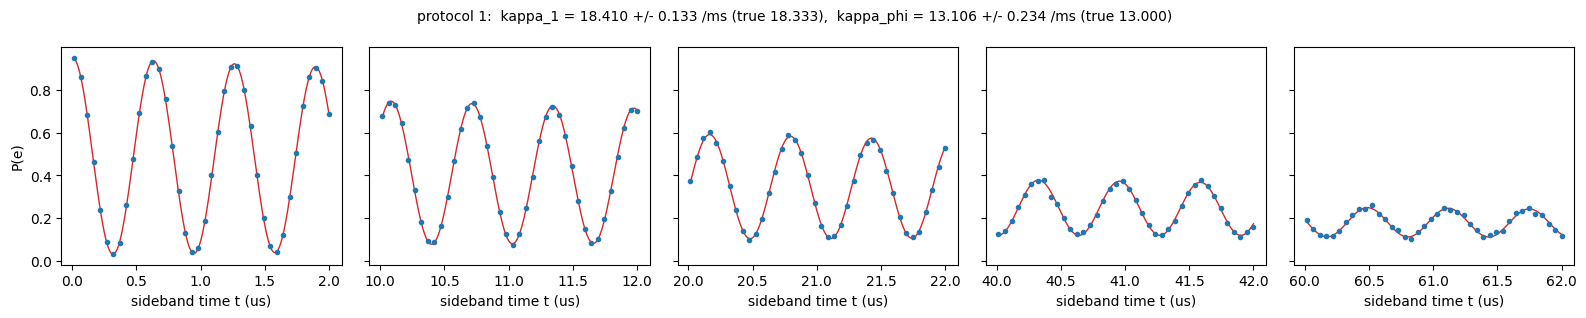

In [9]:
window_starts, window_length, per_window = [0, 10e-6, 20e-6, 40e-6, 60e-6], 2e-6, 40
t1 = np.concatenate([s + np.linspace(0.015e-6, window_length, per_window) for s in window_starts])
pi_g0 = qrot(np.pi, 0) @ g0
p1, s1 = measure([P_e(sideband_map(t) @ pi_g0) for t in t1])
t_swap = np.pi / 2 / g_peak
f1 = fit_oscillation(t1, p1, s1, 0.7 * t_swap, 1.3 * t_swap)

fig, ax = plt.subplots(1, len(window_starts), figsize=(16, 3.2), sharey=True)
for k, s in enumerate(window_starts):
    sel = (t1 >= s) & (t1 <= s + window_length)
    fine = np.linspace(t1[sel].min(), t1[sel].max(), 400)
    ax[k].errorbar(t1[sel] * 1e6, p1[sel], s1[sel], fmt="o", ms=3)
    ax[k].plot(fine * 1e6, oscillation_model(fine, *f1["popt"]), "-", color="#d62728", lw=1)
    ax[k].set_xlabel("sideband time t (us)")
ax[0].set_ylabel("P(e)")
fig.suptitle(f"protocol 1:  kappa_1 = {f1['kappa_1'] * 1e-3:.3f} +/- {f1['kappa_1_err'] * 1e-3:.3f} /ms (true {(G1q + G1c) / 2e3:.3f}),"
             f"  kappa_phi = {f1['kappa_phi'] * 1e-3:.3f} +/- {f1['kappa_phi_err'] * 1e-3:.3f} /ms (true {(Gpq + Gpc) / 2e3:.3f})",
             fontsize=10)
plt.tight_layout(); plt.show()

## Protocol 2 (SidebandDrivenEchoRuntime)

$\pi/2\to J(T/2)\,J^\dagger(T/2)\to R_\phi(\pi/2)$, 8 phases. Fringe contrast = $2\times$ amplitude (`fit_fringe`), then decay (`fit_decay`).

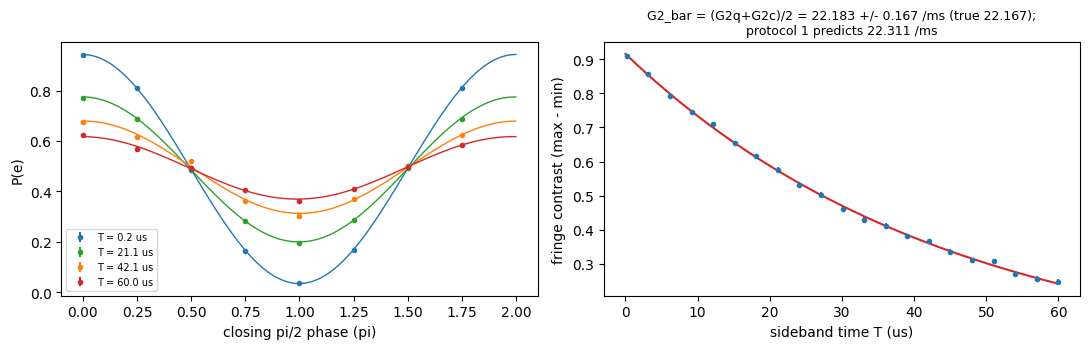

In [10]:
T2 = np.linspace(0.2e-6, 60e-6, 21)
pi2_g0 = qrot(np.pi / 2, 0) @ g0
contrast, contrast_err, fringes = [], [], []
for T in T2:
    v = sideband_map(T / 2, -1) @ sideband_map(T / 2, +1) @ pi2_g0
    P, s = measure([P_e(qrot(np.pi / 2, ph) @ v) for ph in phases])
    c, a_, b_, amp, amp_err = fit_fringe(phases, P, s)
    contrast.append(2 * amp); contrast_err.append(2 * amp_err); fringes.append((P, s, c, a_, b_))
contrast, contrast_err = np.array(contrast), np.array(contrast_err)
f2 = fit_decay(T2, contrast, contrast_err, offset=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
fine_ph = np.linspace(0, 2 * np.pi, 200)
for j, col in zip((0, 7, 14, 20), ("#1f77b4", "#2ca02c", "#ff7f0e", "#d62728")):
    P, s, c, a_, b_ = fringes[j]
    ax[0].errorbar(phases / np.pi, P, s, fmt="o", ms=3, color=col, label=f"T = {T2[j] * 1e6:.1f} us")
    ax[0].plot(fine_ph / np.pi, c + a_ * np.cos(fine_ph) + b_ * np.sin(fine_ph), "-", color=col, lw=1)
ax[0].set_xlabel("closing pi/2 phase (pi)"); ax[0].set_ylabel("P(e)"); ax[0].legend(fontsize=7)
fine = np.linspace(0, T2.max(), 300)
ax[1].errorbar(T2 * 1e6, contrast, contrast_err, fmt="o", ms=3)
ax[1].plot(fine * 1e6, f2["A"] * np.exp(-f2["rate"] * fine), "-", color="#d62728")
ax[1].set_xlabel("sideband time T (us)"); ax[1].set_ylabel("fringe contrast (max - min)")
pred = f1["kappa_1"] / 2 + f1["kappa_phi"]
ax[1].set_title(f"G2_bar = (G2q+G2c)/2 = {f2['rate'] * 1e-3:.3f} +/- {f2['rate_err'] * 1e-3:.3f} /ms (true {(G2q + G2c) / 2e3:.3f});"
                f"\nprotocol 1 predicts {pred * 1e-3:.3f} /ms", fontsize=9)
plt.tight_layout(); plt.show()

## Protocol 3 (SidebandDrivenCoherenceRuntime)

Four preps, each with its own sideband times, $N$ pairs of hann pulses. Fit: `fit_mode_model`, one exact model for all four curves. Shown for interleave flat 0 and 50 ns.

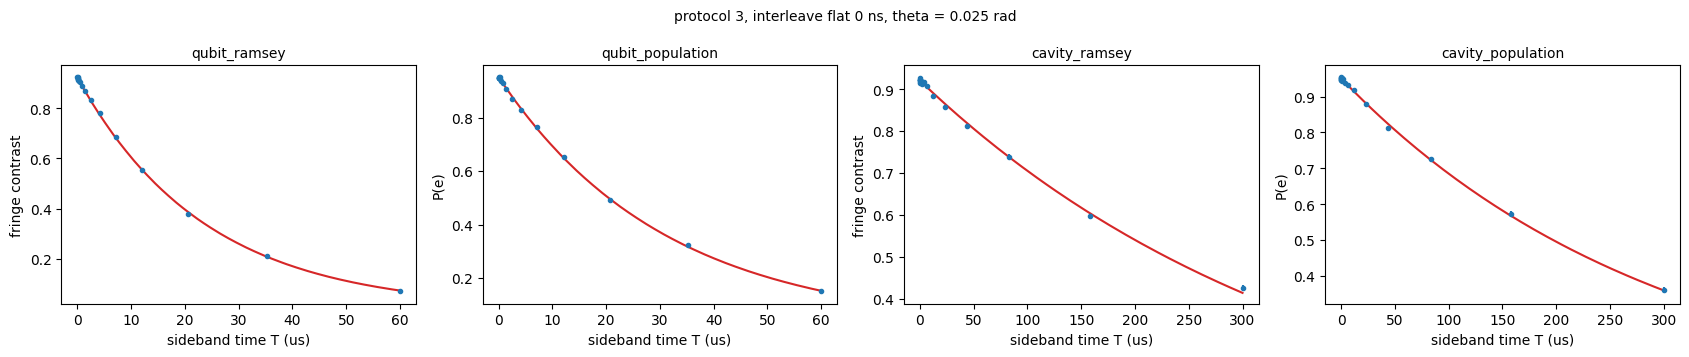

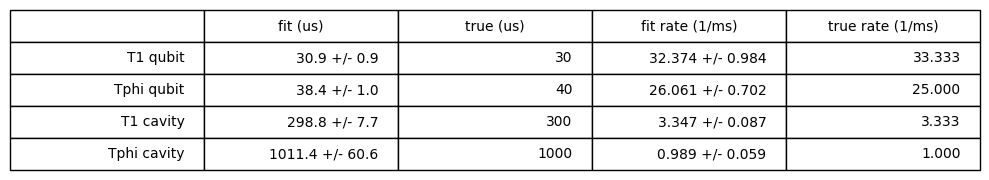

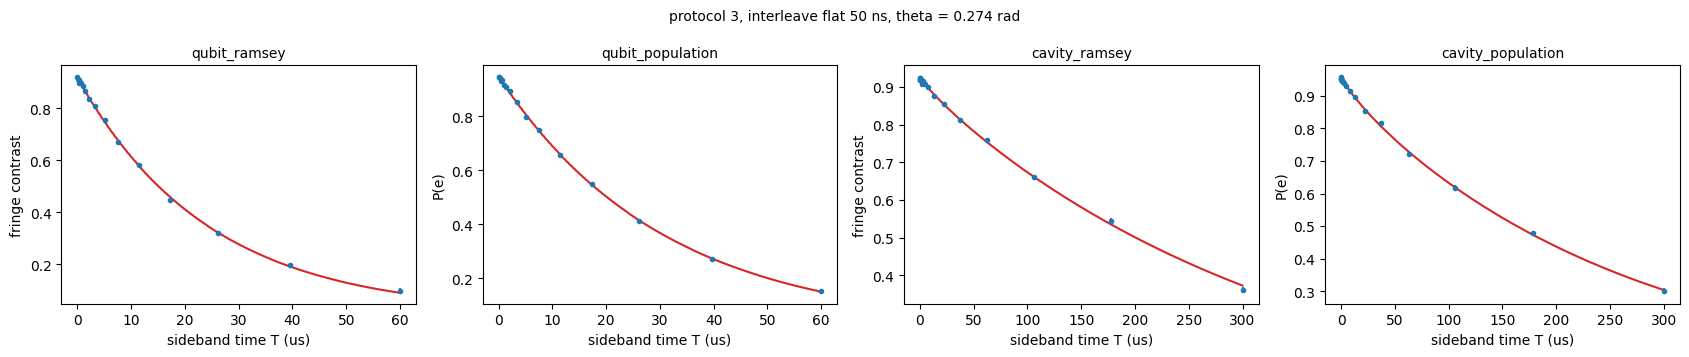

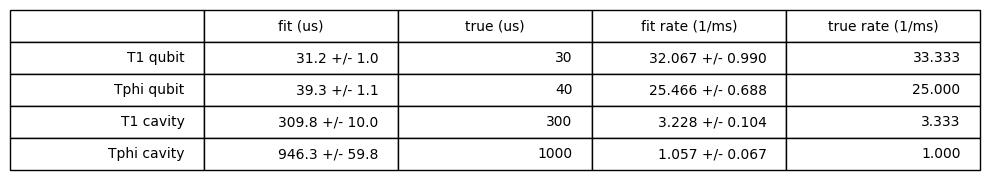

In [11]:
def run_protocol3(flat):
    J = hann(flat)
    angle_steps = (np.pi / 2) * J / swap_area                 # rotation of each sample (swap adds up to pi/2)
    pair = envelope_map(J, -1) @ envelope_map(J, +1)
    pair_time = 2 * J.size / fs
    curves = {}
    for prep in PREPS:
        window = 60e-6 if prep.startswith("qubit") else 300e-6
        N = np.unique(np.concatenate([[0], np.round(np.geomspace(1, window / pair_time, 16)).astype(int)]))
        start = (qrot(np.pi / 2, 0) if prep.endswith("ramsey") else qrot(np.pi, 0)) @ g0
        if prep.startswith("cavity"):
            start = SWAP @ start
        ys, es = [], []
        for n in N:
            v = np.linalg.matrix_power(pair, int(n)) @ start
            if prep.startswith("cavity"):
                v = SWAP @ v
            if prep.endswith("ramsey"):
                P, s = measure([P_e(qrot(np.pi / 2, ph) @ v) for ph in phases])
                _, _, _, amp, amp_err = fit_fringe(phases, P, s)
                ys.append(2 * amp); es.append(2 * amp_err)
            else:
                P, s = measure(P_e(v))
                ys.append(P); es.append(s)
        T = N * pair_time
        ys, es = np.array(ys), np.array(es)
        curves[prep] = dict(t=T, y=ys, y_err=es, fit=fit_decay(T, ys, es, offset=prep.endswith("population")))
    model = fit_mode_model(curves, angle_steps, fs, float(np.sum(angle_steps)))
    return curves, model, float(np.sum(angle_steps))


results3 = {}
for flat in (0.0, 50e-9):
    curves, model, theta = run_protocol3(flat)
    results3[flat] = model
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
    for k, prep in enumerate(PREPS):
        cv = curves[prep]
        fine = np.linspace(0, cv["t"].max(), 200)
        ax[k].errorbar(cv["t"] * 1e6, cv["y"], cv["y_err"], fmt="o", ms=3)
        ax[k].plot(fine * 1e6, model["curve"](prep, fine), "-", color="#d62728", label="one model")
        ax[k].set_title(prep, fontsize=10); ax[k].set_xlabel("sideband time T (us)")
        ax[k].set_ylabel("fringe contrast" if prep.endswith("ramsey") else "P(e)")
    fig.suptitle(f"protocol 3, interleave flat {flat * 1e9:.0f} ns, theta = {theta:.3f} rad", fontsize=10)
    plt.tight_layout(); plt.show()
    # the fitted rates, as a full-width table
    rows = [[lab, f"{1e6 / model[k]:.1f} +/- {1e6 * model[k + '_err'] / model[k] ** 2:.1f}", f"{1e6 / tr:.0f}",
             f"{model[k] * 1e-3:.3f} +/- {model[k + '_err'] * 1e-3:.3f}", f"{tr * 1e-3:.3f}"]
            for lab, k, tr in (("T1 qubit", "G1q", G1q), ("Tphi qubit", "Gphiq", Gpq), ("T1 cavity", "G1c", G1c), ("Tphi cavity", "Gphic", Gpc))]
    fig_t, ax_t = plt.subplots(figsize=(10, 1.9))
    ax_t.axis("off")
    tab = ax_t.table(cellText=rows, colLabels=["", "fit (us)", "true (us)", "fit rate (1/ms)", "true rate (1/ms)"],
                     loc="center", bbox=[0, 0, 1, 1])
    tab.auto_set_font_size(False); tab.set_fontsize(10)
    plt.tight_layout(); plt.show()

## e1f0 sideband (SidebandDrivenOscillationEFRuntime)

**Sequence.** ge $\pi$, ef $\pi$ $\to$ e1f0 sideband for $t$ (real hann ramps, from the setup cell) $\to$ readout classified $g/e/f$. Plus the three calibration shots: prep $g$, $e$, $f$.

**Simulated device.**
- Preparations: a ge $\pi$ that leaves 0.5 % in $g$, an ef $\pi$ that leaves 1 % in $e$, no thermal $e$ (cooled).
- Three overlapping IQ clouds. Each shot's IQ point is drawn and classified by the runtime's nearest-centre rule.

**Fit.** `analyse_ef_oscillation` (the runtime's): $C$ is fitted with the calibration counts, and the theory is multiplied by $C$. Cavity $T_1$, $T_\phi$ are held at their true values. $\Gamma_{\phi,ge}$, $\Gamma_{\phi,gf}$ are nonzero in the simulated truth; the runtime sets them to 0, which is exact because they change no population (1.5).

**Repeats.** The same simulation is repeated to check the error bars (pulls). Expect a positive $\Gamma_{1,ge}$ pull mean from the 1 % ef-$\pi$ failure: a $+0.7\%$ bias (1.5 (e)), against an error of about 0.4 %.


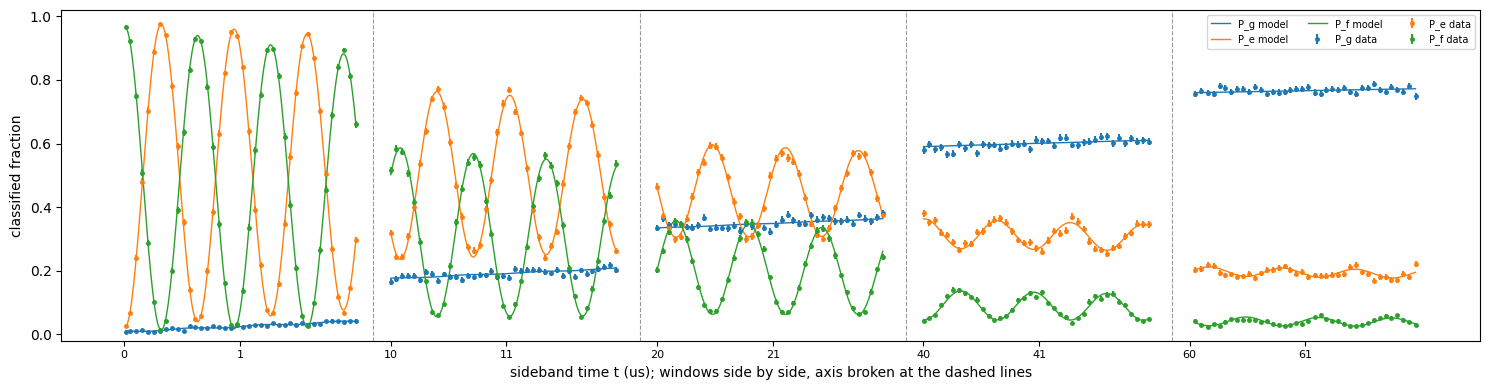

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


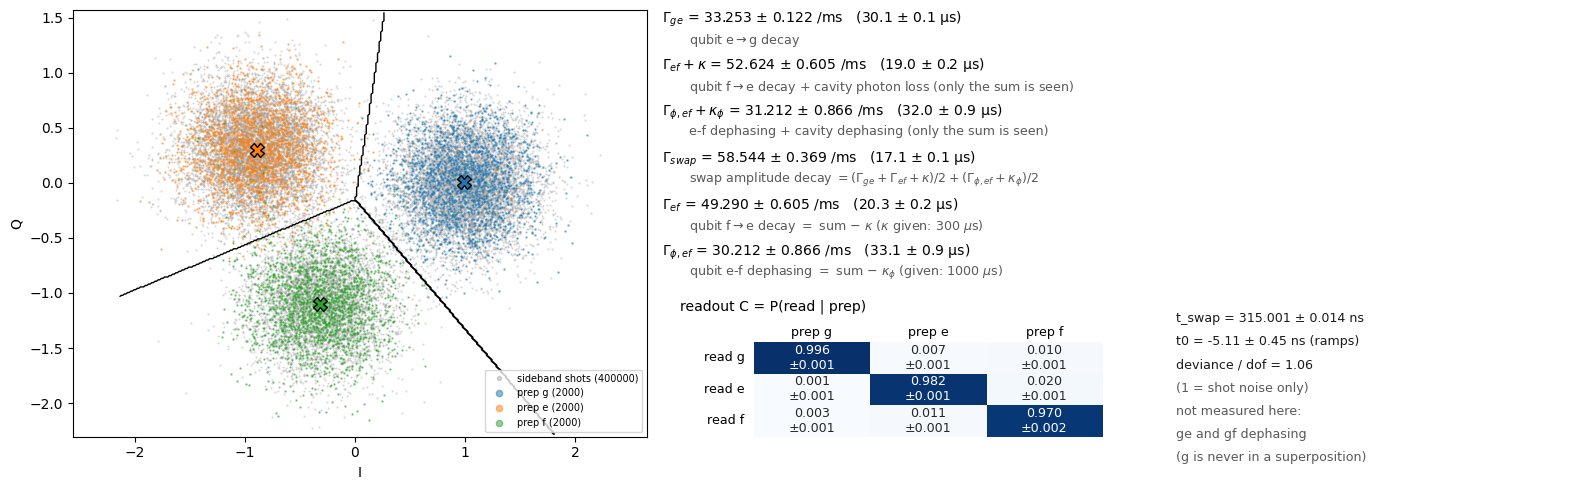

G1ge     fit   33.253 +/-  0.122 /ms   true   33.333   pull -0.66
G1ef     fit   49.290 +/-  0.605 /ms   true   50.000   pull -1.17
Gphi_ef  fit   30.212 +/-  0.866 /ms   true   29.167   pull +1.21
fitted C (columns prep g, e, f):
 [[9.959e-01 6.900e-03 1.050e-02]
 [9.000e-04 9.820e-01 1.960e-02]
 [3.100e-03 1.100e-02 9.699e-01]]


40 repeats, pulls of G1ge, G1ef, Gphi_ef:  mean [ 1.23 -0.3   0.11]   std [1.05 1.07 0.99]


In [12]:
# e1f0 simulated experiment: exact populations with ramps (qutip Liouvillian above, hann rise/fall per sample)
def ef_map(env):
    S = np.eye(81, dtype=complex)
    for e in env:
        S = expm(L_ef_of(g_peak * e) / fs) @ S
    return S
L_ef_of = lambda gg: qt.liouvillian(gg * H_ef, c_ops_ef).full()
rise = hann(0.0)[: int(round(ramp * fs)) // 2]
S_up, S_down = ef_map(rise), ef_map(rise[::-1])
def ef_truth(times, start):
    """P_g, P_e, P_f after the ramped sideband, from the mixture start = populations of |g0>, |e0>, |f0>."""
    rho_start = sum(p * qt.ket2dm(qt.tensor(qt.basis(3, q), qt.basis(3, 0))).full() for q, p in enumerate(start)).ravel(order="F")
    out = []
    for tt in times:
        r = (S_down @ (V_ef @ (np.linalg.solve(V_ef, S_up @ rho_start) * np.exp(w_ef * (tt - ramp))))).reshape(9, 9, order="F")
        out.append([np.real(np.trace(P3(i).full() @ r)) for i in range(3)])
    return np.array(out).T

cycle_ef = 4e-9
starts_ef, length_ef, per_ef = [0, 10e-6, 20e-6, 40e-6, 60e-6], 2e-6, 40
flats_ef = sorted({max(int(round((t - ramp) / cycle_ef)), 1) for s in starts_ef for t in np.linspace(s, s + length_ef, per_ef)})
t_ef = ramp + np.array(flats_ef) * cycle_ef
prep_states_true = prep_chain(0.0, 0.005, 0.01)                         # calibration preps g, e, f: ge pi 0.5 %, ef pi 1 %
P_true_ef = ef_truth(t_ef, prep_states_true[:, 2])
centres_true = np.array([1.0 + 0.0j, -0.9 + 0.3j, -0.3 - 1.1j])        # IQ cloud centres g, e, f
iq_noise = 0.33                                                         # IQ cloud width (overlaps -> classification errors)
held_true = held_rates(cavity_t1_us=1e6 / G1c, cavity_tphi_us=1e6 / Gpc)

def simulate_ef(iterations, rng):
    states = np.array([rng.choice(3, size=iterations, p=P_true_ef[:, k] / P_true_ef[:, k].sum()) for k in range(len(t_ef))]).T
    cal = np.array([rng.choice(3, size=iterations, p=prep_states_true[:, j]) for j in range(3)]).T
    iq = lambda s: centres_true[s] + iq_noise * (rng.normal(size=s.shape) + 1j * rng.normal(size=s.shape))
    return iq(states), iq(cal)

points_ef, calibration_ef = simulate_ef(shots // 2, rng)
an_ef = analyse_ef_oscillation(t_ef, points_ef, calibration_ef, ramp + swap_flat, ramp, None, None, held_true)
fit_ef = an_ef["fit"]
fig, ax = plt.subplots(1, 1, figsize=(15, 4))
plot_ef_populations(ax, an_ef, starts_ef, length_ef)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.6]})
plot_ef_iq(ax[0], points_ef, calibration_ef, an_ef["centres"])
plot_ef_rate_summary(ax[1], an_ef)
plt.tight_layout(); plt.show()
for k, tr in (("G1ge", G1ge), ("G1ef", G1ef), ("Gphi_ef", Gphi_ef)):
    print(f"{k:8s} fit {fit_ef[k] * 1e-3:8.3f} +/- {fit_ef[k + '_err'] * 1e-3:6.3f} /ms   true {tr * 1e-3:8.3f}   "
          f"pull {(fit_ef[k] - tr) / fit_ef[k + '_err']:+.2f}")
print("fitted C (columns prep g, e, f):\n", np.round(fit_ef["confusion"], 4))

# error bars: repeat the simulated experiment, pull = (fit - true) / error
pulls_ef = []
for _ in range(40):
    a_ = analyse_ef_oscillation(t_ef, *simulate_ef(shots // 2, rng), ramp + swap_flat, ramp, None, None, held_true)["fit"]
    pulls_ef.append([(a_[k] - tr) / a_[k + "_err"] for k, tr in (("G1ge", G1ge), ("G1ef", G1ef), ("Gphi_ef", Gphi_ef))])
pulls_ef = np.array(pulls_ef)
print(f"40 repeats, pulls of G1ge, G1ef, Gphi_ef:  mean {np.round(pulls_ef.mean(0), 2)}   std {np.round(pulls_ef.std(0, ddof=1), 2)}")

# 3. Extracted vs true

In [13]:
rows = [
    ("P1  kappa_1 = (G1q+G1c)/2",     f1["kappa_1"],   f1["kappa_1_err"],   (G1q + G1c) / 2),
    ("P1  kappa_phi = (Gphiq+Gphic)/2",f1["kappa_phi"], f1["kappa_phi_err"], (Gpq + Gpc) / 2),
    ("P2  G2_bar = (G2q+G2c)/2",      f2["rate"],      f2["rate_err"],      (G2q + G2c) / 2),
    ("P1 prediction of P2",           f1["kappa_1"] / 2 + f1["kappa_phi"],
                                      np.hypot(f1["kappa_1_err"] / 2, f1["kappa_phi_err"]), (G2q + G2c) / 2),
]
for flat, m in results3.items():
    for lab, k, tr in (("G1q", "G1q", G1q), ("Gphiq", "Gphiq", Gpq), ("G1c", "G1c", G1c), ("Gphic", "Gphic", Gpc)):
        rows.append((f"P3 flat {flat * 1e9:.0f} ns  {lab}", m[k], m[k + "_err"], tr))
    rows.append((f"P3 flat {flat * 1e9:.0f} ns  (G1q+G1c)/2 vs P1", (m["G1q"] + m["G1c"]) / 2,
                 np.hypot(m["G1q_err"], m["G1c_err"]) / 2, (G1q + G1c) / 2))
for k, tr in (("G1ge", G1ge), ("G1ef", G1ef), ("Gphi_ef", Gphi_ef)):
    rows.append((f"e1f0  {k}", fit_ef[k], fit_ef[k + "_err"], tr))
print(f"{'':38} {'fit (1/ms)':>11} {'+/-':>7} {'true':>8} {'pull':>6}")
for lab, f, e, t in rows:
    print(f"{lab:38} {f * 1e-3:11.3f} {e * 1e-3:7.3f} {t * 1e-3:8.3f} {(f - t) / e:+6.2f}")

                                        fit (1/ms)     +/-     true   pull
P1  kappa_1 = (G1q+G1c)/2                   18.410   0.133   18.333  +0.58
P1  kappa_phi = (Gphiq+Gphic)/2             13.106   0.234   13.000  +0.46
P2  G2_bar = (G2q+G2c)/2                    22.183   0.167   22.167  +0.10
P1 prediction of P2                         22.311   0.243   22.167  +0.60
P3 flat 0 ns  G1q                           32.374   0.984   33.333  -0.97
P3 flat 0 ns  Gphiq                         26.061   0.702   25.000  +1.51
P3 flat 0 ns  G1c                            3.347   0.087    3.333  +0.16
P3 flat 0 ns  Gphic                          0.989   0.059    1.000  -0.19
P3 flat 0 ns  (G1q+G1c)/2 vs P1             17.860   0.494   18.333  -0.96
P3 flat 50 ns  G1q                          32.067   0.990   33.333  -1.28
P3 flat 50 ns  Gphiq                        25.466   0.688   25.000  +0.68
P3 flat 50 ns  G1c                           3.228   0.104    3.333  -1.01
P3 flat 50 ns  Gphic     

**Reading the table**

- Protocol 1 gives the two averages.
- Protocol 2 gives one number, which protocol 1 predicts.
- Protocol 3 gives all four rates for any interleave flat, and its averages reproduce protocol 1.

On the device, compare the same rows: a disagreement between protocols beyond the error bars is physics the model does not contain (ramp effects, leakage, a second frequency).